In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

DATASET_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"

print("Dataset folder exists:", os.path.exists(DATASET_PATH))
print("\nAvailable files and folders:")

for item in os.listdir(DATASET_PATH):
    print(item)

Mounted at /content/drive
Dataset folder exists: True

Available files and folders:
archive.zip
motum.zip
brisc_preprocessing_sample
BRISC_preprocessed_256
BRISC_classification_256
MOTUM_preprocessed_2D
MOTUM_preprocessed_256
brisc_mask_visual_inspection.png
BRISC_RAW
BRISC_preprocessed_256_v2
BRISC_mask_visual_inspection_step10.png
BRISC_preprocessing_report.md


Step 2: MOTUM ZIP

In [2]:
import zipfile
import os
from collections import Counter

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

print("MOTUM ZIP exists:", os.path.exists(MOTUM_ZIP))

with zipfile.ZipFile(MOTUM_ZIP, 'r') as zip_ref:

    files = zip_ref.namelist()

    print("\nTotal files and folders:", len(files))

    print("\nFirst 50 items:")
    for item in files[:50]:
        print(item)

    extensions = Counter(
        os.path.splitext(item)[1].lower()
        for item in files
        if not item.endswith("/")
    )

    print("\nFile extension summary:")
    for ext, count in extensions.most_common():
        print(ext if ext else "[No extension]", ":", count)

MOTUM ZIP exists: True

Total files and folders: 1130

First 50 items:
motum/
motum/datacite.yml
motum/derivatives/
motum/derivatives/sub-0001/
motum/derivatives/sub-0001/flair_param.json
motum/derivatives/sub-0001/flair_radiomics.csv
motum/derivatives/sub-0001/flair_seg_label1.nii.gz
motum/derivatives/sub-0001/t1ce_param.json
motum/derivatives/sub-0001/t1ce_radiomics.csv
motum/derivatives/sub-0001/t1ce_seg_label2.nii.gz
motum/derivatives/sub-0001/t1_param.json
motum/derivatives/sub-0001/t1_radiomics.csv
motum/derivatives/sub-0001/t2_param.json
motum/derivatives/sub-0001/t2_radiomics.csv
motum/derivatives/sub-0002/
motum/derivatives/sub-0002/flair_param.json
motum/derivatives/sub-0002/flair_radiomics.csv
motum/derivatives/sub-0002/flair_seg_label1.nii.gz
motum/derivatives/sub-0002/t1ce_param.json
motum/derivatives/sub-0002/t1ce_radiomics.csv
motum/derivatives/sub-0002/t1ce_seg_label2.nii.gz
motum/derivatives/sub-0002/t1_param.json
motum/derivatives/sub-0002/t1_radiomics.csv
motum/deriv

Step 3: Subject ও MRI file count

In [3]:
import zipfile
import os
from collections import Counter

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

with zipfile.ZipFile(MOTUM_ZIP, 'r') as zip_ref:

    files = [
        f for f in zip_ref.namelist()
        if f.endswith(('.nii.gz', '.nii'))
    ]

    subjects = sorted(set(
        f.split('/')[2]
        for f in files
        if len(f.split('/')) > 2
        and f.split('/')[1] in ['derivatives', 'sub-0001']
    ))

    print("Total NIfTI files:", len(files))

    modality_count = Counter()

    for f in files:
        filename = os.path.basename(f).lower()

        for modality in ['flair', 't1ce', 't1', 't2']:
            if filename.startswith(modality):
                modality_count[modality] += 1

    print("\nModality file counts:")
    for modality, count in modality_count.items():
        print(modality, ":", count)

    derivative_subjects = sorted(set(
        f.split('/')[2]
        for f in zip_ref.namelist()
        if f.startswith('motum/derivatives/sub-')
    ))

    print("\nTotal derivative subjects:", len(derivative_subjects))
    print("\nFirst 15 subjects:")
    print(derivative_subjects[:15])

Total NIfTI files: 391

Modality file counts:
flair : 67
t1ce : 67
t1 : 67

Total derivative subjects: 67

First 15 subjects:
['sub-0001', 'sub-0002', 'sub-0003', 'sub-0004', 'sub-0005', 'sub-0006', 'sub-0007', 'sub-0008', 'sub-0009', 'sub-0010', 'sub-0011', 'sub-0012', 'sub-0013', 'sub-0014', 'sub-0015']


Step 4: Inspect MRI Modalities and Segmentation Files

In [4]:
import zipfile
import os

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

with zipfile.ZipFile(MOTUM_ZIP, 'r') as zip_ref:

    all_files = zip_ref.namelist()

    subjects = sorted(set(
        f.split('/')[2]
        for f in all_files
        if len(f.split('/')) > 2
        and f.startswith('motum/derivatives/sub-')
    ))

    for subject in subjects:

        subject_files = [
            os.path.basename(f)
            for f in all_files
            if f.startswith(f'motum/derivatives/{subject}/')
            and f.endswith(('.nii', '.nii.gz'))
        ]

        print(f"\n{subject}")

        for filename in subject_files:
            print("   ", filename)


sub-0001
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0002
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0003
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0004
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0005
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0006
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0007
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0008
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0009
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0010
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0011
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0012
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0013
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0014
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0015
    flair_seg_label1.nii.gz
    t1ce_seg_label2.nii.gz

sub-0016
    flair_seg_l

Step 5: Locate Original MRI Files

In [5]:
import zipfile
import os

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

with zipfile.ZipFile(MOTUM_ZIP, 'r') as zip_ref:

    all_files = zip_ref.namelist()

    print("Top-level folders:")

    top_folders = sorted(set(
        f.split('/')[1]
        for f in all_files
        if f.startswith('motum/') and len(f.split('/')) > 1
    ))

    for folder in top_folders:
        print(folder)

    print("\nAll NIfTI files for sub-0001:")

    for file in all_files:
        if (
            "sub-0001" in file
            and file.endswith((".nii", ".nii.gz"))
        ):
            print(file)

Top-level folders:

DICOM.zip
LICENSE
Participants.xlsx
README.md
datacite.yml
derivatives
sub-0001
sub-0002
sub-0003
sub-0004
sub-0005
sub-0006
sub-0007
sub-0008
sub-0009
sub-0010
sub-0011
sub-0012
sub-0013
sub-0014
sub-0015
sub-0016
sub-0017
sub-0018
sub-0019
sub-0020
sub-0021
sub-0022
sub-0023
sub-0024
sub-0025
sub-0026
sub-0027
sub-0028
sub-0029
sub-0033
sub-0034
sub-0035
sub-0036
sub-0037
sub-0038
sub-0039
sub-0040
sub-0041
sub-0042
sub-0043
sub-0044
sub-0045
sub-0046
sub-0047
sub-0048
sub-0049
sub-0050
sub-0051
sub-0052
sub-0053
sub-0054
sub-0055
sub-0056
sub-0057
sub-0058
sub-0059
sub-0060
sub-0061
sub-0062
sub-0063
sub-0064
sub-0065
sub-0066
sub-0067

All NIfTI files for sub-0001:
motum/derivatives/sub-0001/flair_seg_label1.nii.gz
motum/derivatives/sub-0001/t1ce_seg_label2.nii.gz
motum/sub-0001/anat/sub-0001_flair.nii.gz
motum/sub-0001/anat/sub-0001_t1.nii.gz
motum/sub-0001/anat/sub-0001_t1ce.nii.gz
motum/sub-0001/anat/sub-0001_t2.nii.gz


Step 6: Check MRI Availability for All Subjects

In [7]:
print("Total subjects:", len(df))

print("\nModality availability:")
print(df[["FLAIR", "T1", "T1CE", "T2"]].sum())

print("\nSubjects with all four modalities:")
print(
    df[["FLAIR", "T1", "T1CE", "T2"]]
    .all(axis=1)
    .sum()
)

print("\nSubjects with missing modalities:")
print(
    df[
        ~df[["FLAIR", "T1", "T1CE", "T2"]].all(axis=1)
    ]["Subject"].tolist()
)

Total subjects: 64

Modality availability:
FLAIR    64
T1       64
T1CE     64
T2       64
dtype: int64

Subjects with all four modalities:
64

Subjects with missing modalities:
[]


Step 7: Inspect MRI and Segmentation Properties

In [8]:
!pip install nibabel

In [9]:
import zipfile
import os
import nibabel as nib
import shutil

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

sample_dir = "/content/MOTUM_sample_inspection"
os.makedirs(sample_dir, exist_ok=True)

sample_files = [
    "motum/sub-0001/anat/sub-0001_flair.nii.gz",
    "motum/sub-0001/anat/sub-0001_t1.nii.gz",
    "motum/sub-0001/anat/sub-0001_t1ce.nii.gz",
    "motum/sub-0001/anat/sub-0001_t2.nii.gz",
    "motum/derivatives/sub-0001/flair_seg_label1.nii.gz",
    "motum/derivatives/sub-0001/t1ce_seg_label2.nii.gz"
]

with zipfile.ZipFile(MOTUM_ZIP, 'r') as zip_ref:

    for file_path in sample_files:

        filename = os.path.basename(file_path)
        output_path = os.path.join(sample_dir, filename)

        with zip_ref.open(file_path) as source:
            with open(output_path, "wb") as destination:
                shutil.copyfileobj(source, destination)

print("Sample files extracted successfully.")

print("\nNIfTI Inspection Results:")

for filename in os.listdir(sample_dir):

    file_path = os.path.join(sample_dir, filename)

    nii = nib.load(file_path)

    print("\nFile:", filename)
    print("Shape:", nii.shape)
    print("Voxel spacing:", nii.header.get_zooms())
    print("Orientation:", nib.aff2axcodes(nii.affine))
    print("Data type:", nii.get_data_dtype())

    if "seg" in filename.lower():

        data = nii.get_fdata()

        print("Unique labels:", sorted(set(data.flatten())))

Sample files extracted successfully.

NIfTI Inspection Results:

File: sub-0001_flair.nii.gz
Shape: (192, 256, 21)
Voxel spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(6.750002))
Orientation: ('L', 'P', 'S')
Data type: int16

File: t1ce_seg_label2.nii.gz
Shape: (192, 256, 21)
Voxel spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(6.750002))
Orientation: ('L', 'P', 'S')
Data type: uint16
Unique labels: [np.float64(0.0), np.float64(2.0)]

File: flair_seg_label1.nii.gz
Shape: (192, 256, 21)
Voxel spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(6.750002))
Orientation: ('L', 'P', 'S')
Data type: uint16
Unique labels: [np.float64(0.0), np.float64(1.0)]

File: sub-0001_t1ce.nii.gz
Shape: (192, 256, 21)
Voxel spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(6.750002))
Orientation: ('L', 'P', 'S')
Data type: int16

File: sub-0001_t1.nii.gz
Shape: (192, 256, 21)
Voxel spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(6.750002))
Orient

Step 8: Verify MRI and Mask Alignment

In [10]:
import os
import nibabel as nib
import numpy as np
import zipfile

sample_dir = "/content/MOTUM_sample_inspection"

files = {
    "FLAIR": "sub-0001_flair.nii.gz",
    "T1": "sub-0001_t1.nii.gz",
    "T1CE": "sub-0001_t1ce.nii.gz",
    "T2": "sub-0001_t2.nii.gz",
    "FLAIR_MASK": "flair_seg_label1.nii.gz",
    "T1CE_MASK": "t1ce_seg_label2.nii.gz"
}

images = {}

for name, filename in files.items():
    path = os.path.join(sample_dir, filename)
    images[name] = nib.load(path)

reference = images["FLAIR"]

print("Reference: FLAIR")
print("Shape:", reference.shape)

print("\nAlignment Check:")

for name, nii in images.items():

    same_shape = nii.shape == reference.shape
    same_affine = np.allclose(
        nii.affine,
        reference.affine,
        atol=1e-5
    )

    print(
        name,
        "| Shape match:", same_shape,
        "| Affine match:", same_affine
    )

print("\nMRI Intensity Range:")

for name in ["FLAIR", "T1", "T1CE", "T2"]:

    data = images[name].get_fdata()

    print(
        name,
        "| Min:", np.min(data),
        "| Max:", np.max(data),
        "| Mean:", np.mean(data)
    )

Reference: FLAIR
Shape: (192, 256, 21)

Alignment Check:
FLAIR | Shape match: True | Affine match: True
T1 | Shape match: True | Affine match: True
T1CE | Shape match: True | Affine match: True
T2 | Shape match: True | Affine match: True
FLAIR_MASK | Shape match: True | Affine match: True
T1CE_MASK | Shape match: True | Affine match: True

MRI Intensity Range:
FLAIR | Min: -233.0 | Max: 914.0 | Mean: 82.64836774553571
T1 | Min: 0.0 | Max: 1404.0 | Mean: 129.34890504867312
T1CE | Min: -305.0 | Max: 1916.0 | Mean: 178.32975647941467
T2 | Min: -538.0 | Max: 1746.0 | Mean: 113.78817216176836


Step 9: Read MOTUM Dataset Documentation

In [11]:
import zipfile
import os

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

with zipfile.ZipFile(MOTUM_ZIP, "r") as zip_ref:

    readme_path = "motum/README.md"

    with zip_ref.open(readme_path) as file:
        readme_text = file.read().decode("utf-8")

print(readme_text)

# MOTUM Dataset

This is a public dataset presented at our manuscript titled "A Multi-Center, Multi-Parametric MRI Dataset of Primary and Secondary Brain Tumors" under review in Scientific Data 



## Description

We introduce a multi-center, multi-origin brain tumor MRI (MOTUM) imaging dataset obtained from 67 patients: 29 with high-grade gliomas, 20 with lung metastases, 10 with breast metastases, 2 with gastric metastasis, 4 with ovarian metastasis, and 2 with melanoma metastasis. This dataset includes anonymized digital imaging and communications in medicine (DICOM) files alongside processed FLAIR, T1-weighted, contrast-enhanced T1-weighted, T2-weighted sequences images, segmentation masks of two tumor regions, and clinical data. Our data-sharing initiative is to support the benchmarking of automated tumor segmentation, multi-modal machine learning, and disease differentiation of multi-origin brain tumors in a multi-center setting.


## Data Organization
Multi-contrast MRI, segment

Step 10: Inspect Participants.xlsx

In [12]:
import zipfile
import os
import pandas as pd
from io import BytesIO

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

with zipfile.ZipFile(MOTUM_ZIP, "r") as zip_ref:

    excel_path = "motum/Participants.xlsx"

    with zip_ref.open(excel_path) as file:
        participants = pd.read_excel(BytesIO(file.read()))

print("Dataset shape:", participants.shape)

print("\nColumn names:")
print(participants.columns.tolist())

print("\nFirst 10 rows:")
display(participants.head(10))

print("\nMissing values:")
print(participants.isnull().sum())

Dataset shape: (67, 18)

Column names:
['ID', 'Sex', 'Age at MRI', 'WHO CNS Grade', 'Origin', 'Pathology diagnosis', 'IDH', 'GFAP', 'P53', 'Ki-67', 'Olig-2', 'Surgery or Biopsy', 'Extent of Resection (EOR)', 'Molecular Result', 'Image rating: FLAIR', 'Image rating: T1', 'Image rating: T1-ce', 'Image rating: T2']

First 10 rows:


,ID,Sex,Age at MRI,WHO CNS Grade,Origin,Pathology diagnosis,IDH,GFAP,P53,Ki-67,Olig-2,Surgery or Biopsy,Extent of Resection (EOR),Molecular Result,Image rating: FLAIR,Image rating: T1,Image rating: T1-ce,Image rating: T2
0,sub-0001,Male,79,3,/,Oligodendroglioma,wildtype,+,+/-,35%+,+,Surgery,Near total resection (NTR),/,2,2,1,1
1,sub-0002,Male,54,3,/,Oligodendroglioma,wildtype,+,partially+,30%+,+,Surgery,Subtotal resection (STR),/,2,2,2,2
2,sub-0003,Male,78,3,/,Oligodendroglioma,mutant,+,+,30%+,+,Surgery,Gross total resection (GTR),/,2,2,2,2
3,sub-0004,Male,65,3,/,Astrocytoma,wildtype,+,+,10%+,+,Surgery,Subtotal resection (STR),/,2,1,1,1
4,sub-0005,Male,48,3,/,Oligodendroglioma,mutant,+,partially+,40%+,+,Surgery,Gross total resection (GTR),/,2,2,2,2
5,sub-0006,Male,75,3,/,Astrocytoma,wildtype,+,-,40%+,+,Surgery,Gross total resection (GTR),/,2,2,2,2
6,sub-0007,Female,56,3,/,Oligodendroglioma,wildtype,+,+,70%+,+,Surgery,Gross total resection (GTR),/,2,2,2,2
7,sub-0008,Male,39,3,/,Oligodendroglioma,mutant,+,partially+,50%+,+,Surgery,Gross total resection (GTR),/,2,2,2,2
8,sub-0009,Male,25,3,/,Oligodendroglioma,wildtype,partially+,-,15%+,+,Surgery,Near total resection (NTR),/,2,2,2,2
9,sub-0010,Male,57,3,/,Oligodendroglioma,wildtype,+,-,10%+,+,Surgery,Gross total resection (GTR),/,2,2,2,2



Missing values:
ID                           0
Sex                          0
Age at MRI                   0
WHO CNS Grade                0
Origin                       0
Pathology diagnosis          0
IDH                          0
GFAP                         0
P53                          0
Ki-67                        0
Olig-2                       0
Surgery or Biopsy            0
Extent of Resection (EOR)    0
Molecular Result             0
Image rating: FLAIR          0
Image rating: T1             0
Image rating: T1-ce          0
Image rating: T2             0
dtype: int64


Step 11: Match Clinical Records with MRI Subjects

In [13]:
# Extract subject IDs from the MRI availability DataFrame

mri_subjects = set(df["Subject"].astype(str))

# Extract subject IDs from Participants.xlsx

clinical_subjects = set(participants["ID"].astype(str))

# Compare subject IDs

matched_subjects = mri_subjects & clinical_subjects
missing_mri = clinical_subjects - mri_subjects
missing_clinical = mri_subjects - clinical_subjects

print("Clinical subjects:", len(clinical_subjects))
print("MRI subjects:", len(mri_subjects))
print("Matched subjects:", len(matched_subjects))

print("\nClinical records without original MRI:")
print(sorted(missing_mri))

print("\nMRI subjects without clinical records:")
print(sorted(missing_clinical))

# Diagnosis distribution

print("\nPathology Diagnosis Distribution:")
print(participants["Pathology diagnosis"].value_counts(dropna=False))

print("\nOrigin Distribution:")
print(participants["Origin"].value_counts(dropna=False))

Clinical subjects: 67
MRI subjects: 64
Matched subjects: 64

Clinical records without original MRI:
['sub-0030', 'sub-0031', 'sub-0032']

MRI subjects without clinical records:
[]

Pathology Diagnosis Distribution:
Pathology diagnosis
Glioblastoma                      17
Adenocarcinoma                    14
Breast cancer brain metastasis    10
Oligodendroglioma                  9
Neuroendocrine carcinoma           4
Astrocytoma                        3
Squamous cell carcinoma            3
Ovarian serous adenocarcinoma      2
Melanoma brain metastasis          2
Sarcomatoid carcinoma              1
Ovarian clear cell carcinoma       1
Ovarian carcinosarcoma             1
Name: count, dtype: int64

Origin Distribution:
Origin
/          29
Lung       20
Breast     10
Ovary       4
Stomach     2
Skin        2
Name: count, dtype: int64


Step 12: Analyze Matched Subjects Only

In [14]:
# Keep only subjects with available MRI data

matched_data = participants[
    participants["ID"].isin(mri_subjects)
].copy()

print("Matched dataset shape:", matched_data.shape)

print("\nPathology Diagnosis Distribution:")
print(
    matched_data["Pathology diagnosis"]
    .value_counts(dropna=False)
)

print("\nOrigin Distribution:")
print(
    matched_data["Origin"]
    .value_counts(dropna=False)
)

print("\nWHO CNS Grade Distribution:")
print(
    matched_data["WHO CNS Grade"]
    .value_counts(dropna=False)
)

print("\nImage Rating Distribution:")

rating_columns = [
    "Image rating: FLAIR",
    "Image rating: T1",
    "Image rating: T1-ce",
    "Image rating: T2"
]

for column in rating_columns:
    print("\n", column)
    print(matched_data[column].value_counts(dropna=False))

Matched dataset shape: (64, 18)

Pathology Diagnosis Distribution:
Pathology diagnosis
Glioblastoma                      17
Adenocarcinoma                    12
Breast cancer brain metastasis    10
Oligodendroglioma                  9
Astrocytoma                        3
Squamous cell carcinoma            3
Neuroendocrine carcinoma           3
Ovarian serous adenocarcinoma      2
Melanoma brain metastasis          2
Sarcomatoid carcinoma              1
Ovarian clear cell carcinoma       1
Ovarian carcinosarcoma             1
Name: count, dtype: int64

Origin Distribution:
Origin
/          29
Lung       17
Breast     10
Ovary       4
Stomach     2
Skin        2
Name: count, dtype: int64

WHO CNS Grade Distribution:
WHO CNS Grade
/    35
4    17
3    12
Name: count, dtype: int64

Image Rating Distribution:

 Image rating: FLAIR
Image rating: FLAIR
2    64
Name: count, dtype: int64

 Image rating: T1
Image rating: T1
2    62
1     2
Name: count, dtype: int64

 Image rating: T1-ce
Image r

Step 13: Verify Segmentation Masks for All 64 Subjects

In [15]:
import zipfile
import os

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

with zipfile.ZipFile(MOTUM_ZIP, "r") as zip_ref:

    zip_files = set(zip_ref.namelist())

mask_results = []

for subject in sorted(mri_subjects):

    flair_mask = (
        f"motum/derivatives/{subject}/flair_seg_label1.nii.gz"
    )

    t1ce_mask = (
        f"motum/derivatives/{subject}/t1ce_seg_label2.nii.gz"
    )

    mask_results.append({
        "Subject": subject,
        "FLAIR_Mask": flair_mask in zip_files,
        "T1CE_Mask": t1ce_mask in zip_files
    })

mask_df = pd.DataFrame(mask_results)

print("Total matched subjects:", len(mask_df))

print("\nMask availability:")
print(mask_df[["FLAIR_Mask", "T1CE_Mask"]].sum())

print("\nSubjects with both masks:")
print(
    mask_df[
        mask_df["FLAIR_Mask"] & mask_df["T1CE_Mask"]
    ].shape[0]
)

print("\nSubjects missing any mask:")
display(
    mask_df[
        ~(mask_df["FLAIR_Mask"] & mask_df["T1CE_Mask"])
    ]
)

Total matched subjects: 64

Mask availability:
FLAIR_Mask    64
T1CE_Mask     64
dtype: int64

Subjects with both masks:
64

Subjects missing any mask:


,Subject,FLAIR_Mask,T1CE_Mask


Step 14: Verify All 64 Subjects

In [17]:
import os
import zipfile
import tempfile
import nibabel as nib
import numpy as np
import pandas as pd

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

results = []

with zipfile.ZipFile(MOTUM_ZIP, "r") as zip_ref:

    for subject in sorted(mri_subjects):

        base = f"motum/{subject}"

        files = {
            "FLAIR": f"{base}/anat/{subject}_flair.nii.gz",
            "T1": f"{base}/anat/{subject}_t1.nii.gz",
            "T1CE": f"{base}/anat/{subject}_t1ce.nii.gz",
            "T2": f"{base}/anat/{subject}_t2.nii.gz",
            "FLAIR_MASK": f"motum/derivatives/{subject}/flair_seg_label1.nii.gz",
            "T1CE_MASK": f"motum/derivatives/{subject}/t1ce_seg_label2.nii.gz"
        }

        subject_data = {}

        with tempfile.TemporaryDirectory() as temp_dir:

            for name, archive_path in files.items():

                output_path = os.path.join(
                    temp_dir, name + ".nii.gz"
                )

                with zip_ref.open(archive_path) as source:
                    with open(output_path, "wb") as destination:
                        destination.write(source.read())

                nii = nib.load(output_path)

                # Load image data before temporary files are deleted
                if "MASK" in name:
                    subject_data[name] = nii.get_fdata()
                else:
                    subject_data[name] = {
                        "shape": nii.shape,
                        "affine": nii.affine.copy()
                    }

            reference = subject_data["FLAIR"]

            shape_match = all(
                subject_data[name]["shape"] == reference["shape"]
                for name in ["T1", "T1CE", "T2"]
            )

            affine_match = all(
                np.allclose(
                    subject_data[name]["affine"],
                    reference["affine"],
                    atol=1e-5
                )
                for name in ["T1", "T1CE", "T2"]
            )

            # Check mask geometry
            for mask_name in ["FLAIR_MASK", "T1CE_MASK"]:
                mask_path = os.path.join(
                    temp_dir, mask_name + ".nii.gz"
                )
                mask_nii = nib.load(mask_path)

                if mask_nii.shape != reference["shape"]:
                    shape_match = False

                if not np.allclose(
                    mask_nii.affine,
                    reference["affine"],
                    atol=1e-5
                ):
                    affine_match = False

            results.append({
                "Subject": subject,
                "Shape": reference["shape"],
                "Shape_Match": shape_match,
                "Affine_Match": affine_match,
                "FLAIR_Mask_Labels": str(
                    np.unique(subject_data["FLAIR_MASK"]).tolist()
                ),
                "T1CE_Mask_Labels": str(
                    np.unique(subject_data["T1CE_MASK"]).tolist()
                )
            })

        print("Checked:", subject)

results_df = pd.DataFrame(results)

print("\nTotal subjects:", len(results_df))

print("\nShape match:")
print(results_df["Shape_Match"].value_counts())

print("\nAffine match:")
print(results_df["Affine_Match"].value_counts())

print("\nSubjects with alignment issues:")
display(
    results_df[
        ~(results_df["Shape_Match"] & results_df["Affine_Match"])
    ]
)

print("\nFLAIR mask labels:")
print(results_df["FLAIR_Mask_Labels"].value_counts())

print("\nT1CE mask labels:")
print(results_df["T1CE_Mask_Labels"].value_counts())

Checked: sub-0001
Checked: sub-0002
Checked: sub-0003
Checked: sub-0004
Checked: sub-0005
Checked: sub-0006
Checked: sub-0007
Checked: sub-0008
Checked: sub-0009
Checked: sub-0010
Checked: sub-0011
Checked: sub-0012
Checked: sub-0013
Checked: sub-0014
Checked: sub-0015
Checked: sub-0016
Checked: sub-0017
Checked: sub-0018
Checked: sub-0019
Checked: sub-0020
Checked: sub-0021
Checked: sub-0022
Checked: sub-0023
Checked: sub-0024
Checked: sub-0025
Checked: sub-0026
Checked: sub-0027
Checked: sub-0028
Checked: sub-0029
Checked: sub-0033
Checked: sub-0034
Checked: sub-0035
Checked: sub-0036
Checked: sub-0037
Checked: sub-0038
Checked: sub-0039
Checked: sub-0040
Checked: sub-0041
Checked: sub-0042
Checked: sub-0043
Checked: sub-0044
Checked: sub-0045
Checked: sub-0046
Checked: sub-0047
Checked: sub-0048
Checked: sub-0049
Checked: sub-0050
Checked: sub-0051
Checked: sub-0052
Checked: sub-0053
Checked: sub-0054
Checked: sub-0055
Checked: sub-0056
Checked: sub-0057
Checked: sub-0058
Checked: s

,Subject,Shape,Shape_Match,Affine_Match,FLAIR_Mask_Labels,T1CE_Mask_Labels



FLAIR mask labels:
FLAIR_Mask_Labels
[0.0, 1.0]    64
Name: count, dtype: int64

T1CE mask labels:
T1CE_Mask_Labels
[0.0, 2.0]    61
[0.0, 1.0]     3
Name: count, dtype: int64


Step 15: Investigate T1CE Mask Label Differences

In [18]:
import zipfile
import os
import tempfile
import nibabel as nib
import numpy as np
import pandas as pd

MOTUM_ZIP = os.path.join(DATASET_PATH, "motum.zip")

label_results = []

with zipfile.ZipFile(MOTUM_ZIP, "r") as zip_ref:

    for subject in sorted(mri_subjects):

        mask_path = (
            f"motum/derivatives/{subject}/t1ce_seg_label2.nii.gz"
        )

        with tempfile.TemporaryDirectory() as temp_dir:

            local_path = os.path.join(temp_dir, "mask.nii.gz")

            with zip_ref.open(mask_path) as source:
                with open(local_path, "wb") as destination:
                    destination.write(source.read())

            mask = nib.load(local_path).get_fdata()

            labels, counts = np.unique(
                mask, return_counts=True
            )

            label_results.append({
                "Subject": subject,
                "Labels": labels.tolist(),
                "Label_Counts": dict(zip(
                    labels.tolist(),
                    counts.tolist()
                )),
                "Foreground_Voxels": int(np.count_nonzero(mask))
            })

label_df = pd.DataFrame(label_results)

print("T1CE mask label distribution:")
print(label_df["Labels"].astype(str).value_counts())

print("\nSubjects with label 1:")
display(
    label_df[
        label_df["Labels"].apply(lambda x: 1.0 in x)
    ]
)

print("\nForeground voxel count summary:")
print(label_df["Foreground_Voxels"].describe())

T1CE mask label distribution:
Labels
[0.0, 2.0]    61
[0.0, 1.0]     3
Name: count, dtype: int64

Subjects with label 1:


,Subject,Labels,Label_Counts,Foreground_Voxels
24,sub-0025,"[0.0, 1.0]","{0.0: 6224138, 1.0: 67318}",67318
33,sub-0037,"[0.0, 1.0]","{0.0: 1662642, 1.0: 1358}",1358
35,sub-0039,"[0.0, 1.0]","{0.0: 6219214, 1.0: 72242}",72242



Foreground voxel count summary:
count       64.000000
mean     13405.265625
std      14423.041415
min        291.000000
25%       5654.000000
50%       8928.000000
75%      15396.750000
max      72242.000000
Name: Foreground_Voxels, dtype: float64


Step 16: Visualize MRI and Segmentation Masks

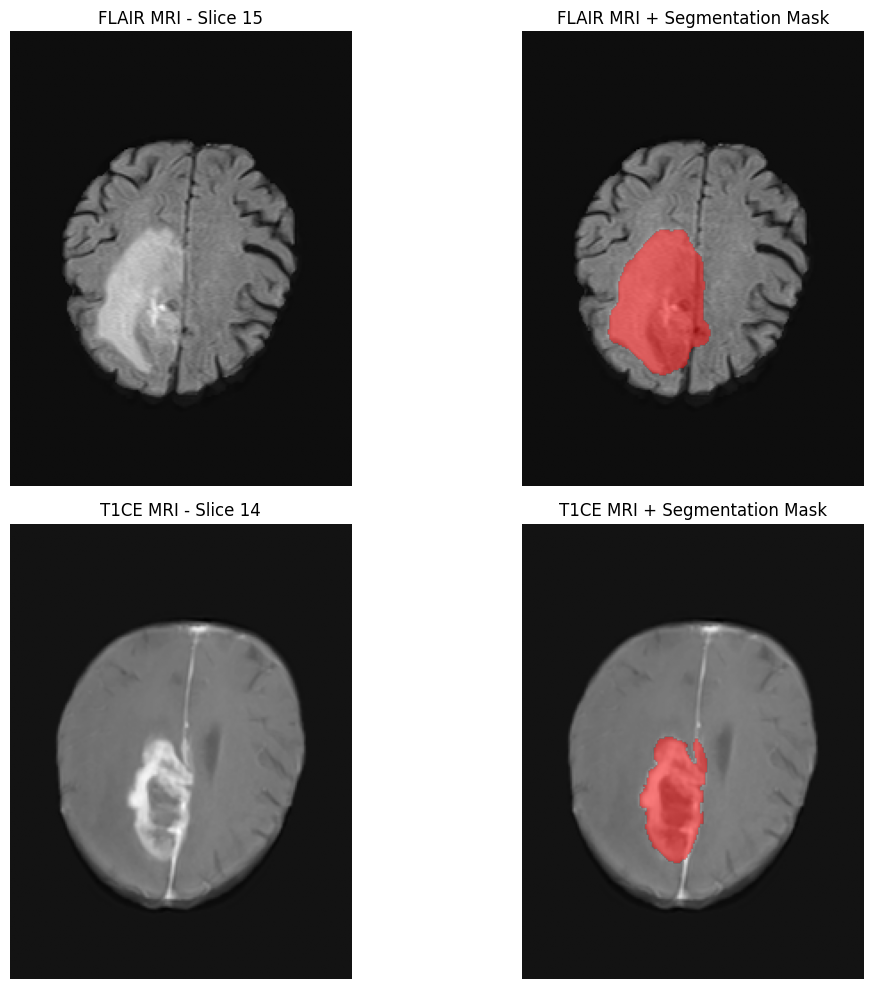

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Select slices with the largest mask area
flair_slice = np.argmax(
    np.count_nonzero(data["FLAIR_MASK"], axis=(0, 1))
)

t1ce_slice = np.argmax(
    np.count_nonzero(data["T1CE_MASK"], axis=(0, 1))
)

# Rotate MRI and masks consistently
flair_img = np.rot90(data["FLAIR"][:, :, flair_slice])
flair_mask = np.rot90(data["FLAIR_MASK"][:, :, flair_slice])

t1ce_img = np.rot90(data["T1CE"][:, :, t1ce_slice])
t1ce_mask = np.rot90(data["T1CE_MASK"][:, :, t1ce_slice])

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# FLAIR MRI
axes[0, 0].imshow(flair_img, cmap="gray")
axes[0, 0].set_title(f"FLAIR MRI - Slice {flair_slice}")
axes[0, 0].axis("off")

# FLAIR overlay
axes[0, 1].imshow(flair_img, cmap="gray")
axes[0, 1].imshow(
    np.ma.masked_where(flair_mask == 0, flair_mask),
    cmap="autumn",
    alpha=0.5
)
axes[0, 1].set_title("FLAIR MRI + Segmentation Mask")
axes[0, 1].axis("off")

# T1CE MRI
axes[1, 0].imshow(t1ce_img, cmap="gray")
axes[1, 0].set_title(f"T1CE MRI - Slice {t1ce_slice}")
axes[1, 0].axis("off")

# T1CE overlay
axes[1, 1].imshow(t1ce_img, cmap="gray")
axes[1, 1].imshow(
    np.ma.masked_where(t1ce_mask == 0, t1ce_mask),
    cmap="autumn",
    alpha=0.5
)
axes[1, 1].set_title("T1CE MRI + Segmentation Mask")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

In [21]:
print("FLAIR shape:", data["FLAIR"].shape)
print("FLAIR mask shape:", data["FLAIR_MASK"].shape)
print("T1CE shape:", data["T1CE"].shape)
print("T1CE mask shape:", data["T1CE_MASK"].shape)

print("FLAIR mask labels:",
      np.unique(data["FLAIR_MASK"]))

print("T1CE mask labels:",
      np.unique(data["T1CE_MASK"]))

FLAIR shape: (192, 256, 21)
FLAIR mask shape: (192, 256, 21)
T1CE shape: (192, 256, 21)
T1CE mask shape: (192, 256, 21)
FLAIR mask labels: [0. 1.]
T1CE mask labels: [0. 2.]


Step 17 — Check Mask Voxel Counts

In [22]:
import numpy as np
import pandas as pd

mask_summary = []

for subject_id in subject_ids:

    flair_mask = load_nifti_array(
        subject_id, "flair_seg_label1.nii.gz"
    )

    t1ce_mask = load_nifti_array(
        subject_id, "t1ce_seg_label2.nii.gz"
    )

    mask_summary.append({
        "Subject": subject_id,
        "FLAIR_Foreground": int(np.count_nonzero(flair_mask)),
        "T1CE_Foreground": int(np.count_nonzero(t1ce_mask)),
        "FLAIR_Labels": np.unique(flair_mask).tolist(),
        "T1CE_Labels": np.unique(t1ce_mask).tolist()
    })

mask_df = pd.DataFrame(mask_summary)

display(mask_df.head(10))

print("Total subjects:", len(mask_df))
print("Empty FLAIR masks:",
      (mask_df["FLAIR_Foreground"] == 0).sum())
print("Empty T1CE masks:",
      (mask_df["T1CE_Foreground"] == 0).sum())

NameError: name 'subject_ids' is not defined

In [23]:
subject_ids = [
    f"sub-{i:04d}"
    for i in list(range(1, 30)) + list(range(33, 68))
]

print("Total subjects:", len(subject_ids))
print(subject_ids[:5])
print(subject_ids[-5:])

Total subjects: 64
['sub-0001', 'sub-0002', 'sub-0003', 'sub-0004', 'sub-0005']
['sub-0063', 'sub-0064', 'sub-0065', 'sub-0066', 'sub-0067']


Step 17A — Define NIfTI Loading Function




In [26]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

def load_nifti_array(subject_id, filename):

    with zipfile.ZipFile(zip_path, "r") as z:
        matches = [
            name for name in z.namelist()
            if subject_id in name and name.endswith(filename)
        ]

        if len(matches) != 1:
            raise FileNotFoundError(
                f"{subject_id}: {filename} - Found {len(matches)} matches"
            )

        with tempfile.TemporaryDirectory() as temp_dir:
            file_path = os.path.join(temp_dir, filename)

            with z.open(matches[0]) as source:
                with open(file_path, "wb") as target:
                    target.write(source.read())

            nii = nib.load(file_path)
            array = nii.get_fdata()

    return array

In [27]:
test_mask = load_nifti_array(
    "sub-0001",
    "flair_seg_label1.nii.gz"
)

print("Shape:", test_mask.shape)
print("Labels:", np.unique(test_mask))

Shape: (192, 256, 21)
Labels: [0. 1.]


Step 17B — Full Mask Voxel Count Check

In [28]:
mask_summary = []

for subject_id in subject_ids:

    flair_mask = load_nifti_array(
        subject_id, "flair_seg_label1.nii.gz"
    )

    t1ce_mask = load_nifti_array(
        subject_id, "t1ce_seg_label2.nii.gz"
    )

    mask_summary.append({
        "Subject": subject_id,
        "FLAIR_Foreground": int(np.count_nonzero(flair_mask)),
        "T1CE_Foreground": int(np.count_nonzero(t1ce_mask)),
        "FLAIR_Labels": np.unique(flair_mask).tolist(),
        "T1CE_Labels": np.unique(t1ce_mask).tolist()
    })

mask_df = pd.DataFrame(mask_summary)

display(mask_df.head(10))

print("Total subjects:", len(mask_df))
print("Empty FLAIR masks:",
      (mask_df["FLAIR_Foreground"] == 0).sum())
print("Empty T1CE masks:",
      (mask_df["T1CE_Foreground"] == 0).sum())

,Subject,FLAIR_Foreground,T1CE_Foreground,FLAIR_Labels,T1CE_Labels
0,sub-0001,20838,8942,"[0.0, 1.0]","[0.0, 2.0]"
1,sub-0002,4904,3427,"[0.0, 1.0]","[0.0, 2.0]"
2,sub-0003,17358,9047,"[0.0, 1.0]","[0.0, 2.0]"
3,sub-0004,22131,16701,"[0.0, 1.0]","[0.0, 2.0]"
4,sub-0005,41768,11469,"[0.0, 1.0]","[0.0, 2.0]"
5,sub-0006,58167,24624,"[0.0, 1.0]","[0.0, 2.0]"
6,sub-0007,21961,12079,"[0.0, 1.0]","[0.0, 2.0]"
7,sub-0008,50686,16284,"[0.0, 1.0]","[0.0, 2.0]"
8,sub-0009,2555,1971,"[0.0, 1.0]","[0.0, 2.0]"
9,sub-0010,28593,13670,"[0.0, 1.0]","[0.0, 2.0]"


Total subjects: 64
Empty FLAIR masks: 0
Empty T1CE masks: 0


Step 18 — Mask Volume Statistics

In [29]:
print("FLAIR Mask Statistics")
display(mask_df["FLAIR_Foreground"].describe())

print("T1CE Mask Statistics")
display(mask_df["T1CE_Foreground"].describe())

FLAIR Mask Statistics


,FLAIR_Foreground
count,64.000000
mean,41147.953125
std,34073.680774
min,1130.000000
25%,17269.750000
50%,35028.000000
75%,55058.250000
max,181684.000000


T1CE Mask Statistics


,T1CE_Foreground
count,64.000000
mean,13405.265625
std,14423.041415
min,291.000000
25%,5654.000000
50%,8928.000000
75%,15396.750000
max,72242.000000


Step 19 — Check MRI Voxel Spacing Across All Subjects

In [30]:
import zipfile
import tempfile
import os
import nibabel as nib
import pandas as pd

spacing_summary = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        matches = [
            name for name in z.namelist()
            if subject_id in name
            and name.endswith(".nii.gz")
            and "FLAIR" in name.upper()
        ]

        if len(matches) != 1:
            print(subject_id, "FLAIR files found:", len(matches))
            continue

        with tempfile.TemporaryDirectory() as temp_dir:

            file_path = os.path.join(temp_dir, "flair.nii.gz")

            with z.open(matches[0]) as source:
                with open(file_path, "wb") as target:
                    target.write(source.read())

            nii = nib.load(file_path)

            spacing = nii.header.get_zooms()[:3]
            shape = nii.shape[:3]

        spacing_summary.append({
            "Subject": subject_id,
            "Shape": shape,
            "Voxel_Spacing": spacing
        })

spacing_df = pd.DataFrame(spacing_summary)

display(spacing_df.head(10))

print("Total subjects checked:", len(spacing_df))
print("Unique voxel spacings:",
      spacing_df["Voxel_Spacing"].nunique())

sub-0001 FLAIR files found: 2
sub-0002 FLAIR files found: 2
sub-0003 FLAIR files found: 2
sub-0004 FLAIR files found: 2
sub-0005 FLAIR files found: 2
sub-0006 FLAIR files found: 2
sub-0007 FLAIR files found: 2
sub-0008 FLAIR files found: 2
sub-0009 FLAIR files found: 2
sub-0010 FLAIR files found: 2
sub-0011 FLAIR files found: 2
sub-0012 FLAIR files found: 2
sub-0013 FLAIR files found: 2
sub-0014 FLAIR files found: 2
sub-0015 FLAIR files found: 2
sub-0016 FLAIR files found: 2
sub-0017 FLAIR files found: 2
sub-0018 FLAIR files found: 2
sub-0019 FLAIR files found: 2
sub-0020 FLAIR files found: 2
sub-0021 FLAIR files found: 2
sub-0022 FLAIR files found: 2
sub-0023 FLAIR files found: 2
sub-0024 FLAIR files found: 2
sub-0025 FLAIR files found: 2
sub-0026 FLAIR files found: 2
sub-0027 FLAIR files found: 2
sub-0028 FLAIR files found: 2
sub-0029 FLAIR files found: 2
sub-0033 FLAIR files found: 2
sub-0034 FLAIR files found: 2
sub-0035 FLAIR files found: 2
sub-0036 FLAIR files found: 2
sub-0037 F

""


Total subjects checked: 0


KeyError: 'Voxel_Spacing'

Step 19A — Identify the Two FLAIR Files

In [31]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:

    for name in z.namelist():
        if "sub-0001" in name and "FLAIR" in name.upper():
            print(name)

motum/derivatives/sub-0001/flair_param.json
motum/derivatives/sub-0001/flair_radiomics.csv
motum/derivatives/sub-0001/flair_seg_label1.nii.gz
motum/sub-0001/anat/sub-0001_flair.nii.gz


Step 19B — Check MRI Voxel Spacing Across All 64 Subjects

In [32]:
import zipfile
import tempfile
import os
import nibabel as nib
import pandas as pd

spacing_summary = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        filename = (
            f"motum/{subject_id}/anat/"
            f"{subject_id}_flair.nii.gz"
        )

        if filename not in z.namelist():
            print("Missing:", subject_id)
            continue

        with tempfile.TemporaryDirectory() as temp_dir:

            file_path = os.path.join(temp_dir, "flair.nii.gz")

            with z.open(filename) as source:
                with open(file_path, "wb") as target:
                    target.write(source.read())

            nii = nib.load(file_path)

            spacing = tuple(
                round(float(x), 6)
                for x in nii.header.get_zooms()[:3]
            )

            shape = nii.shape[:3]

        spacing_summary.append({
            "Subject": subject_id,
            "Shape": shape,
            "Voxel_Spacing": spacing
        })

spacing_df = pd.DataFrame(spacing_summary)

display(spacing_df.head(10))

print("Total subjects checked:", len(spacing_df))

print(
    "Unique voxel spacings:",
    spacing_df["Voxel_Spacing"].nunique()
)

print("\nVoxel spacing distribution:")

display(
    spacing_df["Voxel_Spacing"].value_counts().reset_index(
        name="Number of Subjects"
    )
)

,Subject,Shape,Voxel_Spacing
0,sub-0001,"(192, 256, 21)","(0.9375, 0.9375, 6.750002)"
1,sub-0002,"(260, 320, 21)","(0.75, 0.75, 6.249999)"
2,sub-0003,"(192, 256, 21)","(0.9375, 0.9375, 6.250002)"
3,sub-0004,"(260, 320, 21)","(0.75, 0.75, 6.25)"
4,sub-0005,"(260, 320, 21)","(0.75, 0.75, 6.499999)"
5,sub-0006,"(260, 320, 21)","(0.75, 0.75, 6.250005)"
6,sub-0007,"(260, 320, 21)","(0.75, 0.75, 6.250004)"
7,sub-0008,"(260, 320, 21)","(0.75, 0.75, 6.249999)"
8,sub-0009,"(192, 256, 21)","(0.9375, 0.9375, 6.500004)"
9,sub-0010,"(260, 320, 21)","(0.75, 0.75, 6.249994)"


Total subjects checked: 64
Unique voxel spacings: 48

Voxel spacing distribution:


,Voxel_Spacing,Number of Subjects
0,"(0.75, 0.75, 6.249999)",4
1,"(0.75, 0.75, 6.25)",4
2,"(0.75, 0.75, 5.999998)",3
3,"(0.75, 0.75, 6.250001)",3
4,"(0.75, 0.75, 6.249994)",2
5,"(0.75, 0.75, 6.250005)",2
6,"(0.75, 0.75, 6.000002)",2
7,"(0.75, 0.75, 6.250004)",2
8,"(0.6875, 0.6875, 6.500001)",2
9,"(0.75, 0.75, 6.000003)",2


Step 20 — Analyze Rounded Voxel Spacing and Image Dimensions

In [33]:
# Round voxel spacing to 3 decimal places

spacing_df["Rounded_Spacing"] = spacing_df[
    "Voxel_Spacing"
].apply(
    lambda x: tuple(round(v, 3) for v in x)
)

print("Unique rounded voxel spacings:",
      spacing_df["Rounded_Spacing"].nunique())

print("\nRounded voxel spacing distribution:")

display(
    spacing_df["Rounded_Spacing"]
    .value_counts()
    .reset_index(name="Number of Subjects")
)

print("\nImage dimension distribution:")

display(
    spacing_df["Shape"]
    .value_counts()
    .reset_index(name="Number of Subjects")
)

Unique rounded voxel spacings: 17

Rounded voxel spacing distribution:


,Rounded_Spacing,Number of Subjects
0,"(0.75, 0.75, 6.25)",20
1,"(0.688, 0.688, 6.5)",9
2,"(0.75, 0.75, 6.0)",9
3,"(0.75, 0.75, 6.5)",5
4,"(0.938, 0.938, 6.25)",5
5,"(0.359, 0.359, 7.7)",2
6,"(0.938, 0.938, 6.5)",2
7,"(0.532, 0.532, 6.5)",2
8,"(0.469, 0.469, 5.5)",2
9,"(0.938, 0.938, 6.75)",1



Image dimension distribution:


,Shape,Number of Subjects
0,"(260, 320, 21)",24
1,"(260, 320, 24)",10
2,"(192, 256, 21)",6
3,"(320, 320, 21)",3
4,"(512, 512, 24)",3
5,"(260, 320, 20)",2
6,"(192, 256, 24)",2
7,"(432, 432, 20)",2
8,"(260, 320, 22)",2
9,"(640, 640, 16)",2


Step 21 — Check MRI Modality and Mask Alignment

In [34]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np
import pandas as pd

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

modalities = [
    "flair",
    "t1",
    "t1ce",
    "t2"
]

mask_files = [
    "flair_seg_label1.nii.gz",
    "t1ce_seg_label2.nii.gz"
]

def inspect_nifti(zip_file, internal_path):

    with tempfile.TemporaryDirectory() as temp_dir:

        file_path = os.path.join(
            temp_dir,
            os.path.basename(internal_path)
        )

        with zip_file.open(internal_path) as source:
            with open(file_path, "wb") as target:
                target.write(source.read())

        nii = nib.load(file_path)

        return {
            "Shape": nii.shape,
            "Spacing": tuple(
                round(float(x), 3)
                for x in nii.header.get_zooms()[:3]
            ),
            "Orientation": nib.aff2axcodes(nii.affine),
            "Affine": nii.affine
        }


alignment_results = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        subject_data = {}

        # Check four MRI modalities
        for modality in modalities:

            path = (
                f"motum/{subject_id}/anat/"
                f"{subject_id}_{modality}.nii.gz"
            )

            subject_data[modality] = inspect_nifti(z, path)

        # Check two segmentation masks
        subject_data["flair_mask"] = inspect_nifti(
            z,
            f"motum/derivatives/{subject_id}/flair_seg_label1.nii.gz"
        )

        subject_data["t1ce_mask"] = inspect_nifti(
            z,
            f"motum/derivatives/{subject_id}/t1ce_seg_label2.nii.gz"
        )

        # Compare spatial information
        reference = subject_data["flair"]

        all_shapes_match = all(
            subject_data[key]["Shape"] == reference["Shape"]
            for key in subject_data
        )

        all_orientations_match = all(
            subject_data[key]["Orientation"] == reference["Orientation"]
            for key in subject_data
        )

        all_affines_match = all(
            np.allclose(
                subject_data[key]["Affine"],
                reference["Affine"],
                atol=1e-4
            )
            for key in subject_data
        )

        alignment_results.append({
            "Subject": subject_id,
            "All_Shapes_Match": all_shapes_match,
            "All_Orientations_Match": all_orientations_match,
            "All_Affines_Match": all_affines_match
        })


alignment_df = pd.DataFrame(alignment_results)

print("Total subjects checked:", len(alignment_df))

print("\nShape matching:")
print(alignment_df["All_Shapes_Match"].value_counts())

print("\nOrientation matching:")
print(alignment_df["All_Orientations_Match"].value_counts())

print("\nAffine matching:")
print(alignment_df["All_Affines_Match"].value_counts())

print("\nSubjects with any mismatch:")

display(
    alignment_df[
        ~(
            alignment_df["All_Shapes_Match"]
            & alignment_df["All_Orientations_Match"]
            & alignment_df["All_Affines_Match"]
        )
    ]
)

Total subjects checked: 64

Shape matching:
All_Shapes_Match
True    64
Name: count, dtype: int64

Orientation matching:
All_Orientations_Match
True    64
Name: count, dtype: int64

Affine matching:
All_Affines_Match
True    64
Name: count, dtype: int64

Subjects with any mismatch:


,Subject,All_Shapes_Match,All_Orientations_Match,All_Affines_Match


Step 22 — Analyze MRI Intensity and Segmentation Labels

In [35]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np
import pandas as pd

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

modalities = ["flair", "t1", "t1ce", "t2"]

intensity_results = []
mask_results = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        # Analyze MRI modalities
        for modality in modalities:

            path = (
                f"motum/{subject_id}/anat/"
                f"{subject_id}_{modality}.nii.gz"
            )

            with tempfile.TemporaryDirectory() as temp_dir:

                file_path = os.path.join(temp_dir, "image.nii.gz")

                with z.open(path) as source:
                    with open(file_path, "wb") as target:
                        target.write(source.read())

                image = nib.load(file_path).get_fdata()

            intensity_results.append({
                "Subject": subject_id,
                "Modality": modality.upper(),
                "Minimum": np.min(image),
                "Maximum": np.max(image),
                "Mean": np.mean(image),
                "Standard_Deviation": np.std(image),
                "NaN_Count": np.isnan(image).sum(),
                "Infinite_Count": np.isinf(image).sum()
            })

        # Analyze segmentation masks
        mask_files = {
            "FLAIR_Mask": "flair_seg_label1.nii.gz",
            "T1CE_Mask": "t1ce_seg_label2.nii.gz"
        }

        for mask_name, filename in mask_files.items():

            path = (
                f"motum/derivatives/{subject_id}/{filename}"
            )

            with tempfile.TemporaryDirectory() as temp_dir:

                file_path = os.path.join(temp_dir, "mask.nii.gz")

                with z.open(path) as source:
                    with open(file_path, "wb") as target:
                        target.write(source.read())

                mask = nib.load(file_path).get_fdata()

            mask_results.append({
                "Subject": subject_id,
                "Mask": mask_name,
                "Unique_Labels": tuple(np.unique(mask)),
                "Foreground_Voxels": np.count_nonzero(mask)
            })


intensity_df = pd.DataFrame(intensity_results)
mask_label_df = pd.DataFrame(mask_results)

print("MRI Intensity Analysis")
print("Total MRI records:", len(intensity_df))

print("\nIntensity Summary by Modality:")

display(
    intensity_df.groupby("Modality")[
        ["Minimum", "Maximum", "Mean", "Standard_Deviation"]
    ].agg(["min", "max", "mean"])
)

print("\nNon-finite Value Check:")

display(
    intensity_df.groupby("Modality")[
        ["NaN_Count", "Infinite_Count"]
    ].sum()
)

print("\nSegmentation Mask Label Distribution:")

for mask_name in ["FLAIR_Mask", "T1CE_Mask"]:

    print("\n", mask_name)

    display(
        mask_label_df[
            mask_label_df["Mask"] == mask_name
        ]["Unique_Labels"].value_counts()
    )

print("\nSubjects with unusual T1CE mask labels:")

display(
    mask_label_df[
        (mask_label_df["Mask"] == "T1CE_Mask") &
        (mask_label_df["Unique_Labels"] != (0.0, 2.0))
    ]
)

MRI Intensity Analysis
Total MRI records: 256

Intensity Summary by Modality:


Minimum                    Maximum                             Mean  \
             min    max        mean     min      max         mean        min   
Modality                                                                       
FLAIR    -1418.0  -69.0 -188.956050   470.0   5238.0  1064.171368  37.817660   
T1           0.0    0.0    0.000000   523.0   4679.0  1951.102089  30.467310   
T1CE     -2008.0 -149.0 -579.402214   776.0  11866.0  2836.012901  33.809518   
T2       -2361.0 -102.0 -549.558811   509.0  10022.0  2228.852329  31.809062   

                                 Standard_Deviation                           
                 max        mean                min          max        mean  
Modality                                                                      
FLAIR     292.618398   86.343070          75.314612   603.423392  170.962812  
T1        297.068056  132.710685          58.251023   609.594785  247.435495  
T1CE      643.990280  187.421788          66.677301  1305.100555  351.149196  
T2        406.861855  124.132754          64.222920   923.821525  263.892175


Non-finite Value Check:


,NaN_Count,Infinite_Count
Modality,,
FLAIR,0,0
T1,0,0
T1CE,0,0
T2,0,0



Segmentation Mask Label Distribution:

 FLAIR_Mask


,count
Unique_Labels,
"(0.0, 1.0)",64



 T1CE_Mask


,count
Unique_Labels,
"(0.0, 2.0)",61
"(0.0, 1.0)",3



Subjects with unusual T1CE mask labels:


,Subject,Mask,Unique_Labels,Foreground_Voxels
49,sub-0025,T1CE_Mask,"(0.0, 1.0)",67318
67,sub-0037,T1CE_Mask,"(0.0, 1.0)",1358
71,sub-0039,T1CE_Mask,"(0.0, 1.0)",72242


Step 23 — Analyze MRI Intensity Distribution

In [36]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np
import pandas as pd

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

modalities = ["flair", "t1", "t1ce", "t2"]

distribution_results = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        for modality in modalities:

            path = (
                f"motum/{subject_id}/anat/"
                f"{subject_id}_{modality}.nii.gz"
            )

            with tempfile.TemporaryDirectory() as temp_dir:

                file_path = os.path.join(temp_dir, "image.nii.gz")

                with z.open(path) as source:
                    with open(file_path, "wb") as target:
                        target.write(source.read())

                image = nib.load(file_path).get_fdata()

            nonzero_values = image[image != 0]

            distribution_results.append({
                "Subject": subject_id,
                "Modality": modality.upper(),
                "Zero_Percentage": np.mean(image == 0) * 100,
                "Nonzero_Min": np.min(nonzero_values),
                "Percentile_1": np.percentile(nonzero_values, 1),
                "Median": np.percentile(nonzero_values, 50),
                "Percentile_99": np.percentile(nonzero_values, 99),
                "Nonzero_Max": np.max(nonzero_values)
            })


distribution_df = pd.DataFrame(distribution_results)

print("Total MRI volumes:", len(distribution_df))

print("\nIntensity Distribution Summary:")

display(
    distribution_df.groupby("Modality")[
        [
            "Zero_Percentage",
            "Nonzero_Min",
            "Percentile_1",
            "Median",
            "Percentile_99",
            "Nonzero_Max"
        ]
    ].agg(["min", "max", "mean"]).round(3)
)

Total MRI volumes: 256

Intensity Distribution Summary:


Zero_Percentage                 Nonzero_Min                  \
                     min     max    mean         min    max     mean   
Modality                                                               
FLAIR             19.216  75.632  68.804     -1418.0  -69.0 -188.956   
T1                69.794  82.163  76.619         1.0   72.0    5.174   
T1CE              36.772  77.979  67.482     -2008.0 -149.0 -579.402   
T2                33.224  75.575  68.748     -2361.0 -102.0 -549.559   

         Percentile_1                   Median                  Percentile_99  \
                  min      max     mean    min     max     mean           min   
Modality                                                                        
FLAIR          -174.0   -9.000  -30.939    0.0  1361.0  333.750         247.0   
T1               20.0  581.000  231.443  142.0  1553.0  596.548         178.0   
T1CE           -341.0   -6.462  -72.076    0.0  2874.0  741.563         286.0   
T2             -240.0  -13.000  -55.370    0.0  1568.0  379.063         318.0   

                           Nonzero_Max                     
             max      mean         min      max      mean  
Modality                                                   
FLAIR     2497.0   657.901       470.0   5238.0  1064.171  
T1        2125.0   758.657       523.0   4679.0  1951.102  
T1CE      5204.0  1342.299       776.0  11866.0  2836.013  
T2        5869.0  1495.050       509.0  10022.0  2228.852

Step 24 — Analyze Segmentation Mask Properties

In [37]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np
import pandas as pd

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

mask_files = {
    "FLAIR_Mask": "flair_seg_label1.nii.gz",
    "T1CE_Mask": "t1ce_seg_label2.nii.gz"
}

mask_results = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        for mask_name, filename in mask_files.items():

            path = (
                f"motum/derivatives/{subject_id}/{filename}"
            )

            with tempfile.TemporaryDirectory() as temp_dir:

                file_path = os.path.join(temp_dir, "mask.nii.gz")

                with z.open(path) as source:
                    with open(file_path, "wb") as target:
                        target.write(source.read())

                nii = nib.load(file_path)
                mask = nii.get_fdata()

                voxel_volume = abs(
                    np.linalg.det(nii.affine[:3, :3])
                )

            total_voxels = mask.size
            foreground_voxels = np.count_nonzero(mask)

            labels, counts = np.unique(
                mask,
                return_counts=True
            )

            label_counts = dict(
                zip(labels.astype(int), counts)
            )

            mask_results.append({
                "Subject": subject_id,
                "Mask": mask_name,
                "Total_Voxels": total_voxels,
                "Foreground_Voxels": foreground_voxels,
                "Foreground_Percentage": (
                    foreground_voxels / total_voxels
                ) * 100,
                "Voxel_Volume_mm3": voxel_volume,
                "Foreground_Volume_mm3": (
                    foreground_voxels * voxel_volume
                ),
                "Unique_Labels": tuple(labels.astype(int)),
                "Label_Counts": label_counts
            })


mask_analysis_df = pd.DataFrame(mask_results)

print("Total masks analyzed:", len(mask_analysis_df))

print("\nMask Summary:")

display(
    mask_analysis_df.groupby("Mask")[
        [
            "Foreground_Voxels",
            "Foreground_Percentage",
            "Voxel_Volume_mm3",
            "Foreground_Volume_mm3"
        ]
    ].agg(["min", "max", "mean", "median"]).round(3)
)

print("\nLabel Distribution:")

for mask_name in mask_files:

    print("\n", mask_name)

    display(
        mask_analysis_df[
            mask_analysis_df["Mask"] == mask_name
        ]["Unique_Labels"].value_counts()
    )

print("\nT1CE subjects with label 1:")

display(
    mask_analysis_df[
        (mask_analysis_df["Mask"] == "T1CE_Mask") &
        (mask_analysis_df["Unique_Labels"] == (0, 1))
    ][["Subject", "Foreground_Voxels", "Foreground_Volume_mm3"]]
)

Total masks analyzed: 128

Mask Summary:


Foreground_Voxels                              \
                         min     max       mean   median   
Mask                                                       
FLAIR_Mask              1130  181684  41147.953  35028.0   
T1CE_Mask                291   72242  13405.266   8928.0   

           Foreground_Percentage                      Voxel_Volume_mm3         \
                             min    max   mean median              min    max   
Mask                                                                            
FLAIR_Mask                 0.065  4.643  1.850  1.775            0.994  5.933   
T1CE_Mask                  0.017  1.518  0.599  0.501            0.994  5.933   

                         Foreground_Volume_mm3                          \
             mean median                   min         max        mean   
Mask                                                                     
FLAIR_Mask  3.389  3.516              3972.657  285173.389  117932.901   
T1CE_Mask   3.389  3.516              1023.047  102326.676   38153.675   

                        
                median  
Mask                    
FLAIR_Mask  116583.614  
T1CE_Mask    31382.783


Label Distribution:

 FLAIR_Mask


,count
Unique_Labels,
"(0, 1)",64



 T1CE_Mask


,count
Unique_Labels,
"(0, 2)",61
"(0, 1)",3



T1CE subjects with label 1:


,Subject,Foreground_Voxels,Foreground_Volume_mm3
49,sub-0025,67318,74715.320312
67,sub-0037,1358,4172.136442
71,sub-0039,72242,87322.909725


Step 25 — Verify Segmentation Label Meaning

sub-0001 | FLAIR labels: [0. 1.] | T1CE labels: [0. 2.]
sub-0025 | FLAIR labels: [0. 1.] | T1CE labels: [0. 1.]
sub-0037 | FLAIR labels: [0. 1.] | T1CE labels: [0. 1.]
sub-0039 | FLAIR labels: [0. 1.] | T1CE labels: [0. 1.]


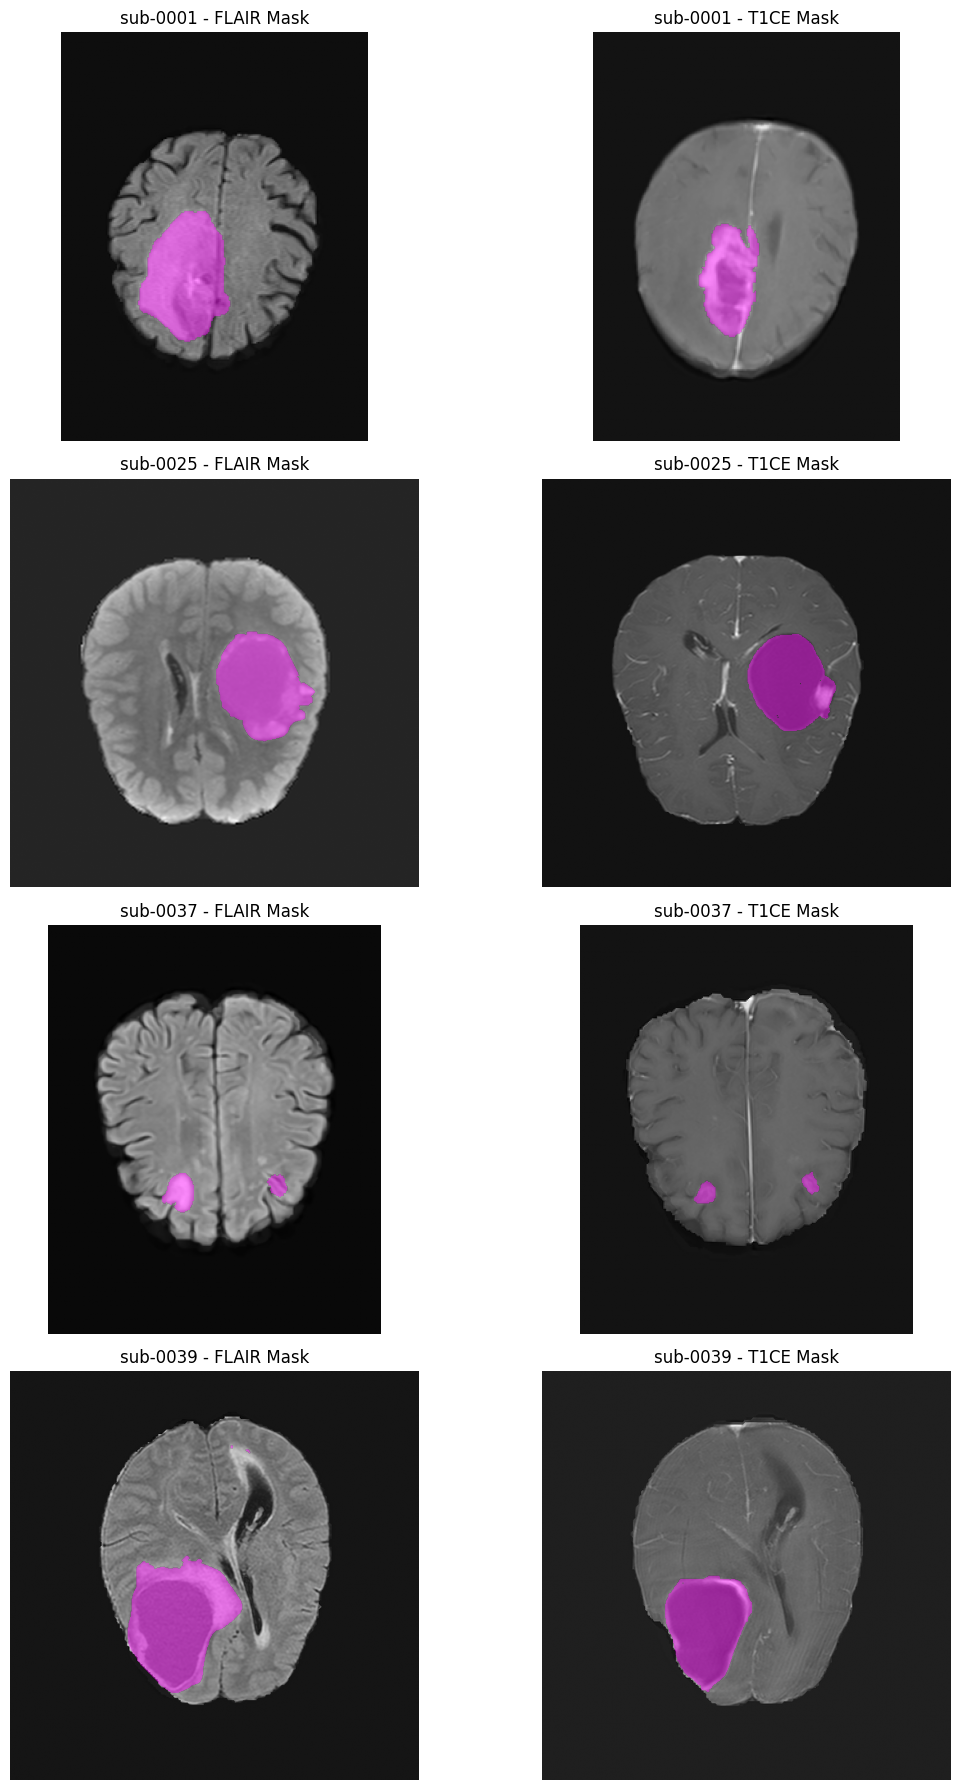

In [43]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

subjects_to_check = [
    "sub-0001",
    "sub-0025",
    "sub-0037",
    "sub-0039"
]

def load_nifti_from_zip(zip_file, internal_path):

    with tempfile.TemporaryDirectory() as temp_dir:

        file_path = os.path.join(
            temp_dir,
            "image.nii.gz"
        )

        with zip_file.open(internal_path) as source:
            with open(file_path, "wb") as target:
                target.write(source.read())

        nii = nib.load(file_path)
        image = nii.get_fdata()

    return image


fig, axes = plt.subplots(
    len(subjects_to_check),
    2,
    figsize=(12, 18)
)

with zipfile.ZipFile(zip_path, "r") as z:

    for row, subject_id in enumerate(subjects_to_check):

        flair_path = (
            f"motum/{subject_id}/anat/"
            f"{subject_id}_flair.nii.gz"
        )

        flair_mask_path = (
            f"motum/derivatives/{subject_id}/"
            "flair_seg_label1.nii.gz"
        )

        t1ce_path = (
            f"motum/{subject_id}/anat/"
            f"{subject_id}_t1ce.nii.gz"
        )

        t1ce_mask_path = (
            f"motum/derivatives/{subject_id}/"
            "t1ce_seg_label2.nii.gz"
        )

        flair = load_nifti_from_zip(z, flair_path)
        flair_mask = load_nifti_from_zip(z, flair_mask_path)

        t1ce = load_nifti_from_zip(z, t1ce_path)
        t1ce_mask = load_nifti_from_zip(z, t1ce_mask_path)

        flair_slice = np.argmax(
            np.sum(flair_mask > 0, axis=(0, 1))
        )

        t1ce_slice = np.argmax(
            np.sum(t1ce_mask > 0, axis=(0, 1))
        )

        flair_image_2d = np.rot90(flair[:, :, flair_slice])
        flair_mask_2d = np.rot90(flair_mask[:, :, flair_slice])

        t1ce_image_2d = np.rot90(t1ce[:, :, t1ce_slice])
        t1ce_mask_2d = np.rot90(t1ce_mask[:, :, t1ce_slice])

        axes[row, 0].imshow(
            flair_image_2d,
            cmap="gray"
        )

        axes[row, 0].imshow(
            np.ma.masked_where(
                flair_mask_2d == 0,
                flair_mask_2d
            ),
            cmap="spring",
            alpha=0.45
        )

        axes[row, 0].set_title(
            f"{subject_id} - FLAIR Mask"
        )

        axes[row, 1].imshow(
            t1ce_image_2d,
            cmap="gray"
        )

        axes[row, 1].imshow(
            np.ma.masked_where(
                t1ce_mask_2d == 0,
                t1ce_mask_2d
            ),
            cmap="spring",
            alpha=0.45
        )

        axes[row, 1].set_title(
            f"{subject_id} - T1CE Mask"
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

        print(
            subject_id,
            "| FLAIR labels:",
            np.unique(flair_mask),
            "| T1CE labels:",
            np.unique(t1ce_mask)
        )

plt.tight_layout()
plt.show()

Step 25B — Save Visualization to Google Drive

In [39]:
output_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_mask_visual_inspection.png"
)

plt.tight_layout()
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Image saved successfully:", output_path)

<Figure size 640x480 with 0 Axes>

Image saved successfully: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_mask_visual_inspection.png


Step 25B — Corrected Save

In [40]:
output_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_mask_visual_inspection.png"
)

plt.savefig(output_path, dpi=200, bbox_inches="tight")

print("Saved:", output_path)
plt.show()

Saved: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_mask_visual_inspection.png


<Figure size 640x480 with 0 Axes>

Step 25C — Create and Save MOTUM Visualization

Saved successfully: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_mask_visual_inspection.png
Number of plotted axes: 8


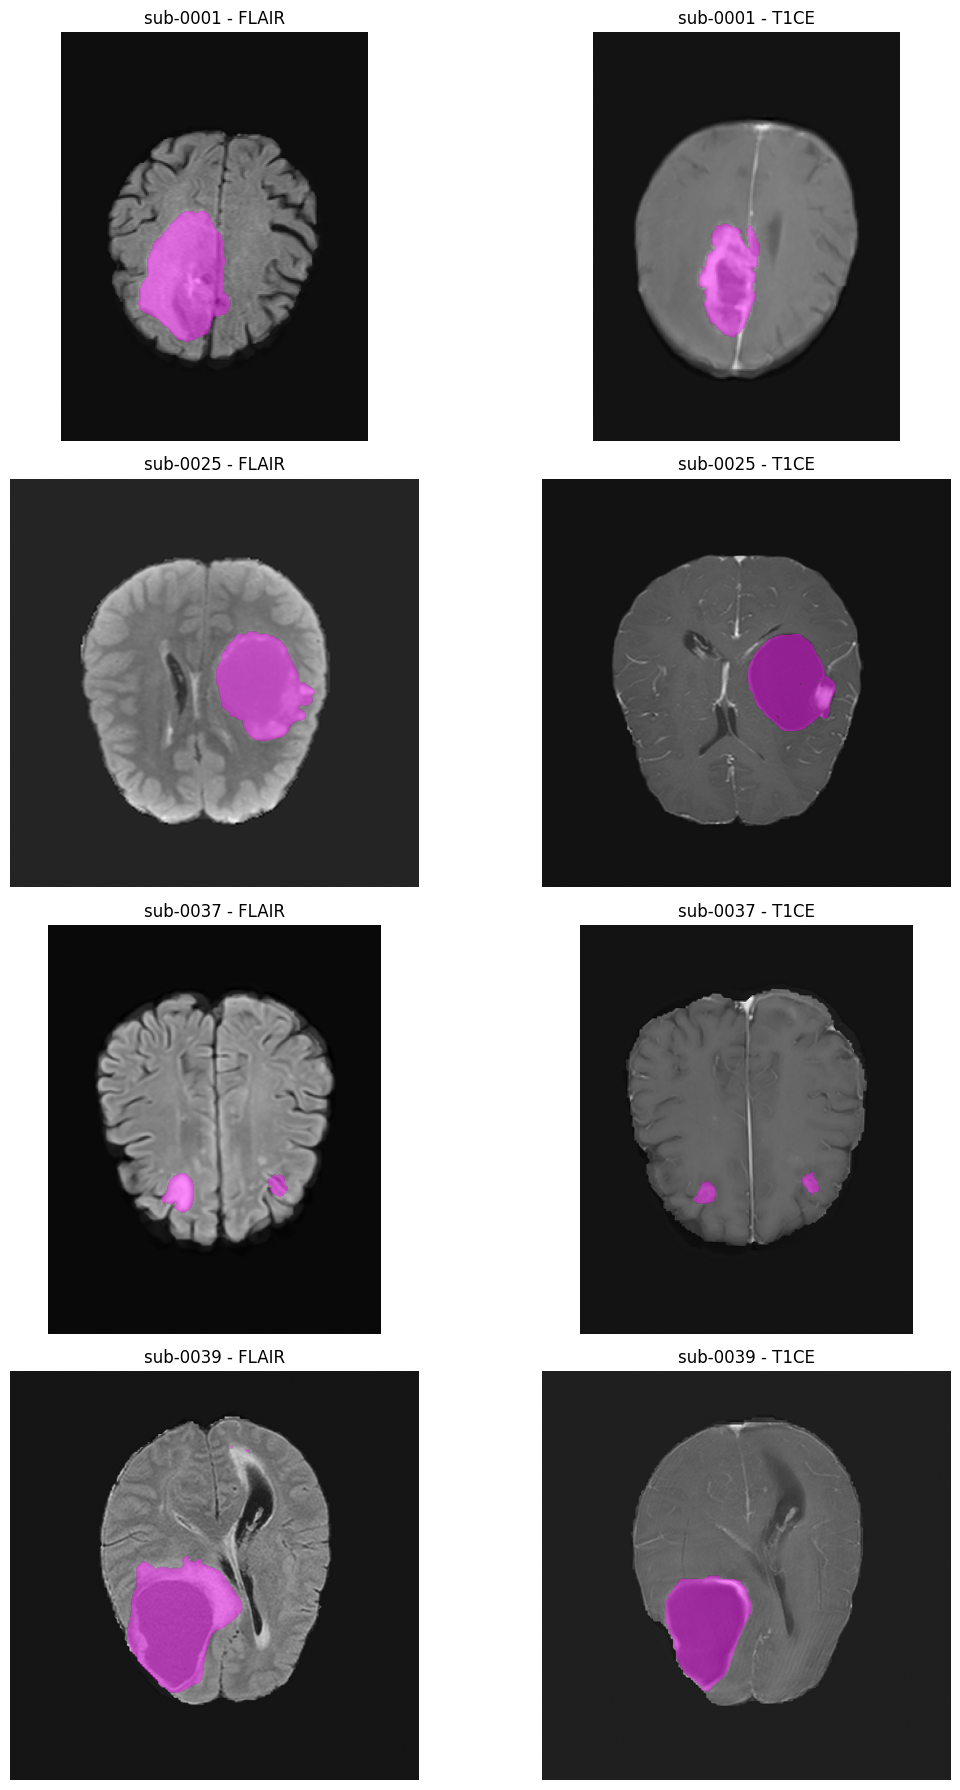

In [44]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

subjects_to_check = [
    "sub-0001",
    "sub-0025",
    "sub-0037",
    "sub-0039"
]

def load_nifti_from_zip(zip_file, internal_path):
    with tempfile.TemporaryDirectory() as temp_dir:
        file_path = os.path.join(temp_dir, "image.nii.gz")

        with zip_file.open(internal_path) as source:
            with open(file_path, "wb") as target:
                target.write(source.read())

        nii = nib.load(file_path)
        return nii.get_fdata()

fig, axes = plt.subplots(4, 2, figsize=(12, 18))

with zipfile.ZipFile(zip_path, "r") as z:

    for row, subject_id in enumerate(subjects_to_check):

        flair_path = f"motum/{subject_id}/anat/{subject_id}_flair.nii.gz"
        flair_mask_path = f"motum/derivatives/{subject_id}/flair_seg_label1.nii.gz"

        t1ce_path = f"motum/{subject_id}/anat/{subject_id}_t1ce.nii.gz"
        t1ce_mask_path = f"motum/derivatives/{subject_id}/t1ce_seg_label2.nii.gz"

        flair = load_nifti_from_zip(z, flair_path)
        flair_mask = load_nifti_from_zip(z, flair_mask_path)

        t1ce = load_nifti_from_zip(z, t1ce_path)
        t1ce_mask = load_nifti_from_zip(z, t1ce_mask_path)

        flair_slice = np.argmax(
            np.sum(flair_mask > 0, axis=(0, 1))
        )

        t1ce_slice = np.argmax(
            np.sum(t1ce_mask > 0, axis=(0, 1))
        )

        flair_img = np.rot90(flair[:, :, flair_slice])
        flair_msk = np.rot90(flair_mask[:, :, flair_slice])

        t1ce_img = np.rot90(t1ce[:, :, t1ce_slice])
        t1ce_msk = np.rot90(t1ce_mask[:, :, t1ce_slice])

        axes[row, 0].imshow(flair_img, cmap="gray")
        axes[row, 0].imshow(
            np.ma.masked_where(flair_msk == 0, flair_msk),
            cmap="spring",
            alpha=0.45
        )
        axes[row, 0].set_title(f"{subject_id} - FLAIR")

        axes[row, 1].imshow(t1ce_img, cmap="gray")
        axes[row, 1].imshow(
            np.ma.masked_where(t1ce_msk == 0, t1ce_msk),
            cmap="spring",
            alpha=0.45
        )
        axes[row, 1].set_title(f"{subject_id} - T1CE")

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

plt.tight_layout()

output_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_mask_visual_inspection.png"
)

fig.savefig(output_path, dpi=200, bbox_inches="tight")

print("Saved successfully:", output_path)
print("Number of plotted axes:", len(fig.axes))

plt.show()

Step 26 — Open the Saved Image

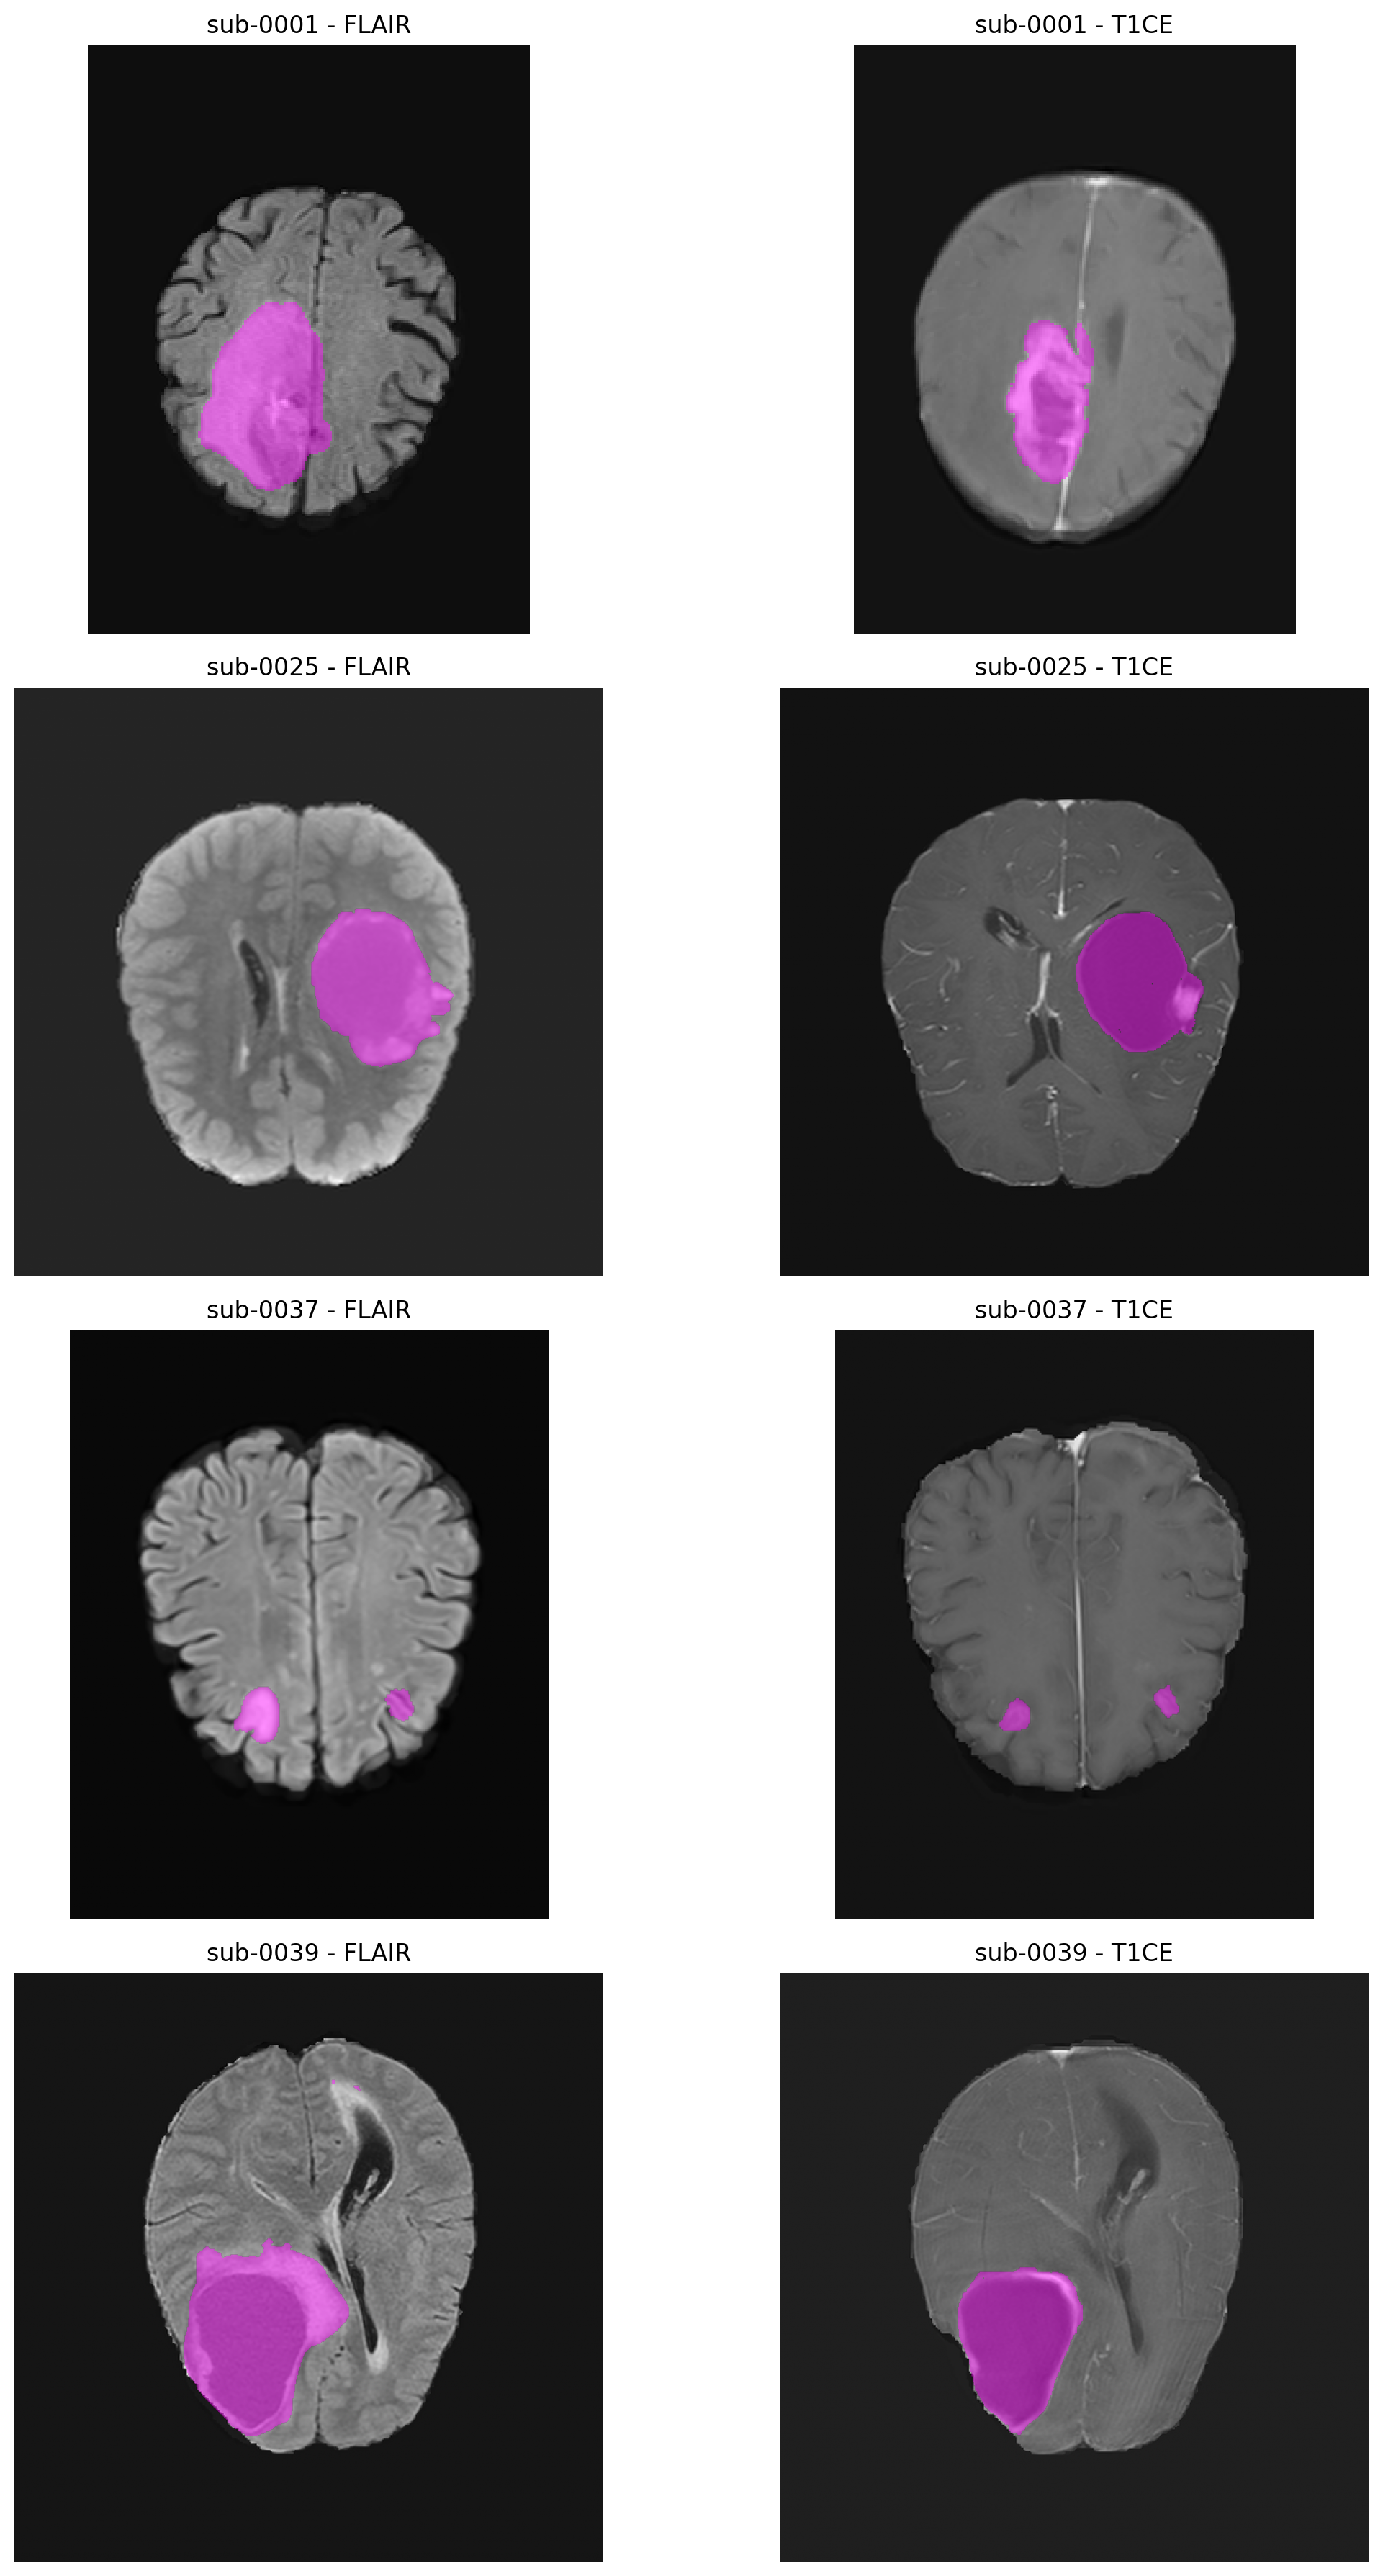

In [45]:
from IPython.display import display, Image

display(Image(
    filename="/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_mask_visual_inspection.png"
))

In [46]:
import numpy as np

for subject_id in subjects_to_check:

    flair_mask = load_nifti_array(
        subject_id, "flair_seg_label1.nii.gz"
    )

    t1ce_mask = load_nifti_array(
        subject_id, "t1ce_seg_label2.nii.gz"
    )

    print(f"\n{subject_id}")

    print("FLAIR foreground voxels:",
          np.count_nonzero(flair_mask))

    print("T1CE foreground voxels:",
          np.count_nonzero(t1ce_mask))

    print("FLAIR mask labels:",
          np.unique(flair_mask))

    print("T1CE mask labels:",
          np.unique(t1ce_mask))


sub-0001
FLAIR foreground voxels: 20838
T1CE foreground voxels: 8942
FLAIR mask labels: [0. 1.]
T1CE mask labels: [0. 2.]

sub-0025
FLAIR foreground voxels: 98553
T1CE foreground voxels: 67318
FLAIR mask labels: [0. 1.]
T1CE mask labels: [0. 1.]

sub-0037
FLAIR foreground voxels: 3166
T1CE foreground voxels: 1358
FLAIR mask labels: [0. 1.]
T1CE mask labels: [0. 1.]

sub-0039
FLAIR foreground voxels: 104843
T1CE foreground voxels: 72242
FLAIR mask labels: [0. 1.]
T1CE mask labels: [0. 1.]


Step 27 — Check All 64 T1CE Mask Encodings

In [47]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

encoding_summary = {}

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        mask_path = (
            f"motum/derivatives/{subject_id}/"
            "t1ce_seg_label2.nii.gz"
        )

        with tempfile.TemporaryDirectory() as temp_dir:

            file_path = os.path.join(temp_dir, "mask.nii.gz")

            with z.open(mask_path) as source:
                with open(file_path, "wb") as target:
                    target.write(source.read())

            mask = nib.load(file_path).get_fdata()

        labels = tuple(np.unique(mask).astype(int))

        encoding_summary[subject_id] = labels

from collections import Counter

print("T1CE mask encoding summary:")
print(Counter(encoding_summary.values()))

print("\nSubjects with unusual encoding:")

for subject_id, labels in encoding_summary.items():
    if labels != (0, 2):
        print(subject_id, labels)

T1CE mask encoding summary:
Counter({(np.int64(0), np.int64(2)): 61, (np.int64(0), np.int64(1)): 3})

Subjects with unusual encoding:
sub-0025 (np.int64(0), np.int64(1))
sub-0037 (np.int64(0), np.int64(1))
sub-0039 (np.int64(0), np.int64(1))


Step 28 — Verify Binary Conversion

In [48]:
import numpy as np

test_labels = {
    "sub-0001": np.array([0, 2]),
    "sub-0025": np.array([0, 1]),
    "sub-0037": np.array([0, 1]),
    "sub-0039": np.array([0, 1])
}

for subject_id, original_mask in test_labels.items():

    binary_mask = (original_mask > 0).astype(np.uint8)

    print(
        subject_id,
        "| Original:", np.unique(original_mask),
        "| Binary:", np.unique(binary_mask)
    )

sub-0001 | Original: [0 2] | Binary: [0 1]
sub-0025 | Original: [0 1] | Binary: [0 1]
sub-0037 | Original: [0 1] | Binary: [0 1]
sub-0039 | Original: [0 1] | Binary: [0 1]


Step 29 — Prepare Binary Masks for All 64 Subjects

In [49]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

output_root = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_binary_masks"
)

os.makedirs(output_root, exist_ok=True)

success_count = 0
failed_subjects = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        subject_output = os.path.join(output_root, subject_id)
        os.makedirs(subject_output, exist_ok=True)

        for modality, filename in [
            ("FLAIR", "flair_seg_label1.nii.gz"),
            ("T1CE", "t1ce_seg_label2.nii.gz")
        ]:

            internal_path = (
                f"motum/derivatives/{subject_id}/{filename}"
            )

            try:
                with tempfile.TemporaryDirectory() as temp_dir:

                    file_path = os.path.join(temp_dir, "mask.nii.gz")

                    with z.open(internal_path) as source:
                        with open(file_path, "wb") as target:
                            target.write(source.read())

                    original_nii = nib.load(file_path)
                    original_mask = original_nii.get_fdata()

                    binary_mask = (
                        original_mask > 0
                    ).astype(np.uint8)

                    output_path = os.path.join(
                        subject_output,
                        f"{modality}_binary.nii.gz"
                    )

                    output_nii = nib.Nifti1Image(
                        binary_mask,
                        original_nii.affine,
                        original_nii.header
                    )

                    output_nii.set_data_dtype(np.uint8)
                    nib.save(output_nii, output_path)

                success_count += 1

            except Exception as error:
                failed_subjects.append(
                    (subject_id, modality, str(error))
                )

print("Total masks saved:", success_count)
print("Expected masks:", len(subject_ids) * 2)
print("Failed masks:", len(failed_subjects))

if failed_subjects:
    print("Failed details:", failed_subjects)

Total masks saved: 128
Expected masks: 128
Failed masks: 0


Step 30 — Verify Saved Binary Masks

In [50]:
import os
import nibabel as nib
import numpy as np

output_root = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_binary_masks"
)

checked_count = 0
failed_checks = []

for subject_id in subject_ids:

    for modality in ["FLAIR", "T1CE"]:

        mask_path = os.path.join(
            output_root,
            subject_id,
            f"{modality}_binary.nii.gz"
        )

        try:
            mask_nii = nib.load(mask_path)
            mask = mask_nii.get_fdata()

            labels = np.unique(mask)

            if not np.all(np.isin(labels, [0, 1])):
                failed_checks.append(
                    (subject_id, modality, "Invalid labels")
                )

            if np.count_nonzero(mask) == 0:
                failed_checks.append(
                    (subject_id, modality, "Empty mask")
                )

            if mask_nii.get_data_dtype() != np.dtype("uint8"):
                failed_checks.append(
                    (subject_id, modality, "Incorrect data type")
                )

            checked_count += 1

        except Exception as error:
            failed_checks.append(
                (subject_id, modality, str(error))
            )

print("Total masks checked:", checked_count)
print("Failed checks:", len(failed_checks))
print("Failed details:", failed_checks[:10])

Total masks checked: 128
Failed checks: 0
Failed details: []


Step 31 — MRI Intensity Normalization

In [51]:
import numpy as np

subject_id = "sub-0001"

modalities = ["flair", "t1", "t1ce", "t2"]

for modality in modalities:

    image = load_nifti_array(
        subject_id,
        f"{subject_id}_{modality}.nii.gz"
    )

    nonzero = image[image != 0]

    print(f"\n{modality.upper()}")
    print("Shape:", image.shape)
    print("Nonzero voxels:", len(nonzero))
    print("Minimum:", np.min(nonzero))
    print("Maximum:", np.max(nonzero))
    print("Mean:", np.mean(nonzero))
    print("Standard deviation:", np.std(nonzero))


FLAIR
Shape: (192, 256, 21)
Nonzero voxels: 305681
Minimum: -233.0
Maximum: 914.0
Mean: 279.07846415053604
Standard deviation: 180.47161830923497

T1
Shape: (192, 256, 21)
Nonzero voxels: 249729
Minimum: 3.0
Maximum: 1404.0
Mean: 534.6311601776325
Standard deviation: 119.23073676954306

T1CE
Shape: (192, 256, 21)
Nonzero voxels: 327360
Minimum: -305.0
Maximum: 1916.0
Mean: 562.2878421309873
Standard deviation: 323.921711895752

T2
Shape: (192, 256, 21)
Nonzero voxels: 311521
Minimum: -538.0
Maximum: 1746.0
Mean: 377.0251154817813
Standard deviation: 317.5957612949874


Step 32 — Test Z-score Normalization

In [52]:
import numpy as np

subject_id = "sub-0001"
modalities = ["flair", "t1", "t1ce", "t2"]

for modality in modalities:

    image = load_nifti_array(
        subject_id,
        f"{subject_id}_{modality}.nii.gz"
    ).astype(np.float32)

    brain_mask = image != 0

    normalized = np.zeros_like(image, dtype=np.float32)

    brain_values = image[brain_mask]

    mean_value = np.mean(brain_values)
    std_value = np.std(brain_values)

    normalized[brain_mask] = (
        brain_values - mean_value
    ) / (std_value + 1e-8)

    print(f"\n{modality.upper()}")
    print("Normalized mean:", np.mean(normalized[brain_mask]))
    print("Normalized std:", np.std(normalized[brain_mask]))
    print("Background values:", np.unique(normalized[~brain_mask]))


FLAIR
Normalized mean: 1.5973555e-08
Normalized std: 1.0
Background values: [0.]

T1
Normalized mean: -4.301538e-08
Normalized std: 1.0
Background values: [0.]

T1CE
Normalized mean: 0.0
Normalized std: 0.99999994
Background values: [0.]

T2
Normalized mean: -7.837052e-09
Normalized std: 0.99999994
Background values: [0.]


Step 33 — Normalize All 64 Subjects

In [53]:
import zipfile
import tempfile
import os
import nibabel as nib
import numpy as np

zip_path = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/motum.zip"

output_root = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_normalized"
)

os.makedirs(output_root, exist_ok=True)

modalities = ["flair", "t1", "t1ce", "t2"]

success_count = 0
failed_files = []

with zipfile.ZipFile(zip_path, "r") as z:

    for subject_id in subject_ids:

        subject_output = os.path.join(
            output_root, subject_id
        )
        os.makedirs(subject_output, exist_ok=True)

        for modality in modalities:

            filename = f"{subject_id}_{modality}.nii.gz"
            internal_path = (
                f"motum/{subject_id}/anat/{filename}"
            )

            try:
                with tempfile.TemporaryDirectory() as temp_dir:

                    file_path = os.path.join(temp_dir, filename)

                    with z.open(internal_path) as source:
                        with open(file_path, "wb") as target:
                            target.write(source.read())

                    original_nii = nib.load(file_path)
                    image = original_nii.get_fdata(
                        dtype=np.float32
                    )

                    brain_mask = image != 0
                    brain_values = image[brain_mask]

                    mean_value = np.mean(brain_values)
                    std_value = np.std(brain_values)

                    normalized = np.zeros_like(
                        image, dtype=np.float32
                    )

                    normalized[brain_mask] = (
                        brain_values - mean_value
                    ) / (std_value + 1e-8)

                    output_nii = nib.Nifti1Image(
                        normalized,
                        original_nii.affine,
                        original_nii.header
                    )

                    output_nii.set_data_dtype(np.float32)

                    output_path = os.path.join(
                        subject_output,
                        f"{modality}_normalized.nii.gz"
                    )

                    nib.save(output_nii, output_path)

                success_count += 1

            except Exception as error:
                failed_files.append(
                    (subject_id, modality, str(error))
                )

print("Total normalized volumes:", success_count)
print("Expected volumes:", len(subject_ids) * 4)
print("Failed files:", len(failed_files))

if failed_files:
    print(failed_files[:10])

Total normalized volumes: 256
Expected volumes: 256
Failed files: 0


Step 34 — Normalized Volume Verification

In [54]:
import os
import nibabel as nib
import numpy as np

root = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_normalized"

modalities = ["flair", "t1", "t1ce", "t2"]

checked = 0
failed = []

for subject_id in subject_ids:
    for modality in modalities:

        path = os.path.join(
            root,
            subject_id,
            f"{modality}_normalized.nii.gz"
        )

        try:
            nii = nib.load(path)
            data = nii.get_fdata(dtype=np.float32)

            if not np.isfinite(data).all():
                raise ValueError("NaN or Inf found")

            if data.shape != nii.header.get_data_shape():
                raise ValueError("Shape mismatch")

            checked += 1

        except Exception as error:
            failed.append((subject_id, modality, str(error)))

print("Volumes checked:", checked)
print("Expected:", 256)
print("Failed:", len(failed))
print("Errors:", failed[:10])

Volumes checked: 256
Expected: 256
Failed: 0
Errors: []


Step 35 — Subject-wise Dataset Split

In [55]:
import os
import json
import numpy as np

output_root = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_normalized"
)

rng = np.random.RandomState(42)
shuffled_ids = np.array(subject_ids.copy())
rng.shuffle(shuffled_ids)

train_ids = shuffled_ids[:44].tolist()
val_ids = shuffled_ids[44:54].tolist()
test_ids = shuffled_ids[54:].tolist()

split_data = {
    "train": train_ids,
    "validation": val_ids,
    "test": test_ids
}

split_path = os.path.join(
    output_root, "subject_split.json"
)

with open(split_path, "w") as f:
    json.dump(split_data, f, indent=4)

print("Train subjects:", len(train_ids))
print("Validation subjects:", len(val_ids))
print("Test subjects:", len(test_ids))

print("Total:", len(train_ids) + len(val_ids) + len(test_ids))
print("Unique subjects:", len(set(train_ids + val_ids + test_ids)))
print("Split saved:", split_path)

Train subjects: 44
Validation subjects: 10
Test subjects: 10
Total: 64
Unique subjects: 64
Split saved: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_normalized/subject_split.json


Step 36 — 2D Slice Extraction

In [56]:
import os
import json
import nibabel as nib
import numpy as np

base = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"

normalized_root = os.path.join(base, "MOTUM_normalized")
mask_root = os.path.join(base, "MOTUM_binary_masks")
output_root = os.path.join(base, "MOTUM_2D_slices")

os.makedirs(output_root, exist_ok=True)

# Load the saved subject split
with open(os.path.join(normalized_root, "subject_split.json"), "r") as f:
    split_data = json.load(f)

modalities = ["flair", "t1", "t1ce", "t2"]

saved_count = 0
failed = []

for split_name, ids in split_data.items():

    split_folder = os.path.join(output_root, split_name)
    os.makedirs(split_folder, exist_ok=True)

    for subject_id in ids:

        try:
            images = {}
            reference_nii = None

            # Load four normalized MRI modalities
            for modality in modalities:

                path = os.path.join(
                    normalized_root,
                    subject_id,
                    f"{modality}_normalized.nii.gz"
                )

                nii = nib.load(path)
                data = nii.get_fdata(dtype=np.float32)

                if reference_nii is None:
                    reference_nii = nii
                else:
                    if data.shape != reference_nii.shape:
                        raise ValueError("MRI shape mismatch")

                    if not np.allclose(
                        nii.affine, reference_nii.affine
                    ):
                        raise ValueError("MRI affine mismatch")

                images[modality] = data

            # Load the two separate binary masks
            masks = {}

            for mask_name in ["FLAIR_binary", "T1CE_binary"]:

                mask_path = os.path.join(
                    mask_root,
                    subject_id,
                    f"{mask_name}.nii.gz"
                )

                mask_nii = nib.load(mask_path)
                mask_data = mask_nii.get_fdata()

                if mask_data.shape != reference_nii.shape:
                    raise ValueError(f"{mask_name} shape mismatch")

                if not np.allclose(
                    mask_nii.affine, reference_nii.affine
                ):
                    raise ValueError(f"{mask_name} affine mismatch")

                masks[mask_name] = (
                    mask_data > 0
                ).astype(np.uint8)

            # Extract slices along the third axis
            number_of_slices = reference_nii.shape[2]

            for slice_index in range(number_of_slices):

                image_stack = np.stack(
                    [
                        images[m][:, :, slice_index]
                        for m in modalities
                    ],
                    axis=-1
                )

                flair_mask = masks["FLAIR_binary"][:, :, slice_index]
                t1ce_mask = masks["T1CE_binary"][:, :, slice_index]

                filename = (
                    f"{subject_id}_slice_{slice_index:03d}.npz"
                )

                save_path = os.path.join(
                    split_folder, filename
                )

                np.savez_compressed(
                    save_path,
                    images=image_stack,
                    flair_mask=flair_mask,
                    t1ce_mask=t1ce_mask,
                    subject_id=subject_id,
                    slice_index=slice_index,
                    modalities=np.array(modalities)
                )

                saved_count += 1

        except Exception as error:
            failed.append((subject_id, str(error)))

print("Total 2D slices saved:", saved_count)
print("Failed subjects:", len(failed))
print("Errors:", failed[:10])
print("Output folder:", output_root)

Total 2D slices saved: 1370
Failed subjects: 0
Errors: []
Output folder: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_2D_slices


Step 37 — Final Dataset Verification

In [57]:
import os
import numpy as np

total_files = 0
invalid_files = []

for split_name in ["train", "validation", "test"]:

    folder = os.path.join(output_root, split_name)
    files = [
        f for f in os.listdir(folder)
        if f.endswith(".npz")
    ]

    print(split_name, "slices:", len(files))
    total_files += len(files)

    # Check one saved slice from each non-empty split
    if files:
        sample_path = os.path.join(folder, files[0])

        with np.load(sample_path) as sample:

            images = sample["images"]
            flair_mask = sample["flair_mask"]
            t1ce_mask = sample["t1ce_mask"]

            if images.ndim != 3 or images.shape[2] != 4:
                invalid_files.append(files[0])

            if not np.isin(flair_mask, [0, 1]).all():
                invalid_files.append(files[0])

            if not np.isin(t1ce_mask, [0, 1]).all():
                invalid_files.append(files[0])

            if not np.isfinite(images).all():
                invalid_files.append(files[0])

print("\nTotal slices:", total_files)
print("Invalid sample files:", len(invalid_files))
print("Invalid files:", invalid_files)

train slices: 929
validation slices: 225
test slices: 216

Total slices: 1370
Invalid sample files: 0
Invalid files: []


Final Step — Complete Slice Verification

In [58]:
import os
import numpy as np

total_checked = 0
errors = []

for split in ["train", "validation", "test"]:

    folder = os.path.join(output_root, split)

    for filename in os.listdir(folder):

        if not filename.endswith(".npz"):
            continue

        path = os.path.join(folder, filename)

        try:
            with np.load(path) as data:

                images = data["images"]
                flair_mask = data["flair_mask"]
                t1ce_mask = data["t1ce_mask"]

                if images.ndim != 3 or images.shape[2] != 4:
                    raise ValueError("Invalid MRI shape")

                if flair_mask.shape != images.shape[:2]:
                    raise ValueError("FLAIR mask shape mismatch")

                if t1ce_mask.shape != images.shape[:2]:
                    raise ValueError("T1CE mask shape mismatch")

                if not np.isfinite(images).all():
                    raise ValueError("NaN or Inf found")

                if not np.isin(flair_mask, [0, 1]).all():
                    raise ValueError("Invalid FLAIR mask labels")

                if not np.isin(t1ce_mask, [0, 1]).all():
                    raise ValueError("Invalid T1CE mask labels")

                total_checked += 1

        except Exception as error:
            errors.append((filename, str(error)))

print("Total slices checked:", total_checked)
print("Expected slices:", 1370)
print("Failed slices:", len(errors))
print("Errors:", errors[:10])

Total slices checked: 1370
Expected slices: 1370
Failed slices: 0
Errors: []
